###**Group:**
1. Suha Khalil
2. Sandra Igboabuchukwu
3. Noelle Haviland

##**Large Project 1**
##**Title:** Scalable Diabetes Risk Analytics & Classification using PySpark

##Runtime Calculation Notebook

###Preprocessing runtime:

In [5]:
%pip install pyspark

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install pandas

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.9 MB 14.4 MB/s eta 0:00:01
   ----------------------- ---------------- 6.3/10.9 MB 21.9 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 21.6 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
#Import Libraries

import pyspark
#import requests
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from pyspark.sql.functions import (
    col,
    sum,
    min,
    max,
    count,
    round as spark_round
)

from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.mllib.evaluation import BinaryClassificationMetrics, MulticlassMetrics
from pyspark.ml.functions import vector_to_array

#from google.colab import files

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import time
import os
import psutil
import builtins

In [9]:
%pip install pyspark

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
print("Available CPU cores:", os.cpu_count())

print(
    "Total RAM (GB):",
    round(psutil.virtual_memory().total / (1024**3), 2)
)

Available CPU cores: 16
Total RAM (GB): 15.34


In [11]:
import pyspark
import os

print("PySpark location:", pyspark.__file__)

PySpark location: C:\Users\cassa\AppData\Roaming\Python\Python314\site-packages\pyspark\__init__.py


In [12]:
import os
import pyspark

# Identify the PySpark installation directory
SPARK_HOME = os.path.dirname(pyspark.__file__)

print("SPARK_HOME:", SPARK_HOME)
print("Directory exists:", os.path.isdir(SPARK_HOME))

SPARK_HOME: C:\Users\cassa\AppData\Roaming\Python\Python314\site-packages\pyspark
Directory exists: True


In [13]:
import os
import pyspark

SPARK_HOME = os.path.dirname(pyspark.__file__)

SPARK_CLASS = os.path.join(
    SPARK_HOME,
    "bin",
    "spark-class.cmd"
)

print("SPARK_HOME:", SPARK_HOME)
print("SPARK_CLASS:", SPARK_CLASS)
print("File exists:", os.path.isfile(SPARK_CLASS))

SPARK_HOME: C:\Users\cassa\AppData\Roaming\Python\Python314\site-packages\pyspark
SPARK_CLASS: C:\Users\cassa\AppData\Roaming\Python\Python314\site-packages\pyspark\bin\spark-class.cmd
File exists: True


In [14]:
import pyspark
import sys

print("PySpark version:", pyspark.__version__)
print("Python version:", sys.version)

PySpark version: 4.2.1
Python version: 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]


In [15]:
import subprocess

result = subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True
)

print(result.stderr or result.stdout)

openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment Temurin-17.0.20.1+1 (build 17.0.20.1+1)
OpenJDK 64-Bit Server VM Temurin-17.0.20.1+1 (build 17.0.20.1+1, mixed mode, sharing)



In [16]:
import subprocess

result = subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True
)

print(result.stderr or result.stdout)

openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment Temurin-17.0.20.1+1 (build 17.0.20.1+1)
OpenJDK 64-Bit Server VM Temurin-17.0.20.1+1 (build 17.0.20.1+1, mixed mode, sharing)



In [17]:
from pyspark.sql import SparkSession

# Create a local Spark session
spark = (
    SparkSession.builder
    .appName("DiabetesSparkTest")
    .master("local[2]")
    .getOrCreate()
)

# Display Spark information
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)

# Test Spark DataFrame execution
spark.range(5).show()

C:\Users\cassa\AppData\Roaming\Python\Python314\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark version: 4.2.1
Spark master: local[2]
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



In [18]:
# Start the Spark Master on Windows

import subprocess
import time
import os
import pyspark

# Locate the PySpark installation
SPARK_HOME = os.path.dirname(pyspark.__file__)

# Locate the Windows Spark launcher
SPARK_CLASS = os.path.join(
    SPARK_HOME,
    "bin",
    "spark-class.cmd"
)

print("Spark launcher exists:", os.path.isfile(SPARK_CLASS))

# Start Spark Master using Windows Command Prompt
master_process = subprocess.Popen(
    [
        os.environ.get("COMSPEC", "cmd.exe"),
        "/c",
        SPARK_CLASS,
        "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1",
        "--port", "7077",
        "--webui-port", "8080"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(5)

print(
    "Master process running:",
    master_process.poll() is None
)

Spark launcher exists: True
Master process running: True


In [4]:
# Start 1 Spark worker with 1 core on Windows

import subprocess
import time
import os

worker_process = subprocess.Popen(
    [
        os.environ.get("COMSPEC", "cmd.exe"),
        "/c",
        SPARK_CLASS,
        "org.apache.spark.deploy.worker.Worker",
        "--cores", "1",
        "--memory", "2G",
        "--webui-port", "8081",
        "spark://127.0.0.1:7077"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(5)

print(
    "Worker process running:",
    worker_process.poll() is None
)

Worker process running: True


In [19]:
#connect to master /worker
spark = (
    SparkSession.builder
    .appName("DiabetesMLBenchmark")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .getOrCreate()
)

In [20]:
#verify if the standalone setup is active
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)
print("Application ID:", spark.sparkContext.applicationId)

Spark version: 4.2.1
Spark master: local[2]
Default parallelism: 2
Application ID: local-1793350041956


In [21]:
# Stop the existing local Spark session
spark.stop()

print("Local Spark session stopped.")

Local Spark session stopped.


In [22]:
import socket

for port, name in [(7077, "Spark Master"), (8081, "Spark Worker UI")]:
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        status = s.connect_ex(("127.0.0.1", port))

    print(f"{name} available:", status == 0)

Spark Master available: True
Spark Worker UI available: False


In [9]:
from pyspark.sql import SparkSession

# Create a new Spark application
spark = (
    SparkSession.builder
    .appName("DiabetesStatisticalBenchmark_1Executor")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.cores.max", "1")
    .config("spark.executor.memory", "1g")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)
print("Application ID:", spark.sparkContext.applicationId)

Spark version: 4.2.1
Spark master: spark://127.0.0.1:7077
Default parallelism: 2
Application ID: app-20261030035224-0000


In [23]:
#debugging/verification

import subprocess

result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print(result.stdout)

67488 Jps
12692 Master
66856 SparkSubmit



Master → the Spark master

Worker → one worker

SparkSubmit → Spark driver/application

CoarseGrainedExecutorBackend → the executor process launched by that worker

Jps → just the command we used to list Java processes


### **Data Preprocessing**

We must load the data and complete the preprocessing steps before running the machine-learning models. Since this is not my part of the experiment, I will run it here outside of the experiement.

In [24]:
# Upload the file
#uploaded = files.upload()

In [26]:
from pyspark.sql import SparkSession

In [27]:
spark = (
    SparkSession.builder
    .appName("DiabetesSparkProject")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.cores.max", "1")
    .config("spark.executor.memory", "1g")
    .getOrCreate()
)

print("Spark master:", spark.sparkContext.master)

Spark master: spark://127.0.0.1:7077


In [29]:
from pyspark.sql import SparkSession

# Stop the previous Spark session if one exists
try:
    spark.stop()
    print("Previous Spark session stopped.")
except (NameError, RuntimeError):
    print("No active Spark session to stop.")

# Connect to the standalone Spark Master
spark = (
    SparkSession.builder
    .appName("DiabetesSparkProject")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.cores.max", "1")
    .config("spark.executor.memory", "1g")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Application ID:", spark.sparkContext.applicationId)

Previous Spark session stopped.
Spark version: 4.2.1
Spark master: spark://127.0.0.1:7077
Application ID: app-20261030050742-0003


In [30]:
# Test whether the Spark executor can process a job

test_count = spark.range(10).count()

print("Spark test result:", test_count)

Spark test result: 10


In [31]:
from pathlib import Path

# Locate the project folder
project_root = Path.cwd()

if not (project_root / "data").is_dir():
    project_root = project_root.parent

# Dataset path
file_path = (
    project_root
    / "data"
    / "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
)

# Load dataset
df = spark.read.csv(
    file_path.resolve().as_uri(),
    header=True,
    inferSchema=True
)

# Display first five observations
df.show(5, truncate=False)

+---------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|Diabetes_binary|HighBP|HighChol|CholCheck|BMI |Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex|Age |Education|Income|
+---------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|0.0            |1.0   |0.0     |1.0      |26.0|0.0   |0.0   |0.0                 |1.0         |0.0   |1.0    |0.0              |1.0          |0.0        |3.0    |5.0     |30.0    |0.0     |1.0|4.0 |6.0      |8.0   |
|0.0            |1.0   |1.0     |1.0      |26.0|1.0   |1.0   |0.0                 |0.0         |1.0   |0.0    |0.0              |1.0

In [33]:

from pathlib import Path
from pyspark.sql.functions import sum, col
from pyspark.ml.feature import VectorAssembler, StandardScaler

# 1. Load dataset
# Use the project data folder instead of the old Downloads path

project_root = Path.cwd()

if not (project_root / "data").is_dir():
    project_root = project_root.parent

file_path = (
    project_root
    / "data"
    / "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
)

df = spark.read.csv(
    file_path.resolve().as_uri(),
    header=True,
    inferSchema=True
)

# 2. Validate dimensions
row_count = df.count()
column_count = len(df.columns)

# 3. Check missing values
null_counts = df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

null_counts.collect()   # force Spark to perform the check

# 4. Check exact duplicate rows
distinct_rows = df.distinct().count()
duplicate_rows = row_count - distinct_rows

# 5. Define target and predictors
label_col = "Diabetes_binary"

feature_cols = [
    c for c in df.columns
    if c != label_col
]

# 6. Split into training and test sets
train, test = df.randomSplit(
    [0.8, 0.2],
    seed=42
)

# 7. Assemble predictor features
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

train_assembled = assembler.transform(train)
test_assembled = assembler.transform(test)

# 8. Fit StandardScaler using training data only
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaledFeatures",
    withStd=True,
    withMean=False
)

scaler_model = scaler.fit(
    train_assembled
)

# 9. Apply scaler to training and test data
train_scaled = scaler_model.transform(
    train_assembled
)

test_scaled = scaler_model.transform(
    test_assembled
)

# Force Spark to execute the final preprocessing pipelines
train_rows = train_scaled.count()
test_rows = test_scaled.count()


print(f"Dataset: {row_count:,} rows, {column_count} columns")
print(f"Duplicate rows: {duplicate_rows:,}")
print(f"Training rows: {train_rows:,}")
print(f"Test rows: {test_rows:,}")
print("Preprocessing complete.")


Dataset: 70,692 rows, 22 columns
Duplicate rows: 1,635
Training rows: 56,487
Test rows: 14,205
Preprocessing complete.


### **The warmup time for the machine learning workflow**


In [34]:

import time
import builtins
import numpy as np

from pyspark.sql import functions as F
from pyspark.sql.types import NumericType
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

# Benchmark one complete statistical analysis run

# Clear Spark cache
spark.catalog.clearCache()

# Begin runtime
start_time = time.perf_counter()

# Use the original validated dataset
validated_df = df

# 1. Descriptive statistics
descriptive_stats = validated_df.describe()
descriptive_results = descriptive_stats.collect()

# 2. Dataset dimensions
total_rows = validated_df.count()
total_columns = len(validated_df.columns)

# 3. Diabetes frequency and percentage
diabetes_frequency = (
    validated_df
    .groupBy("Diabetes_binary")
    .agg(F.count("*").alias("Frequency"))
    .withColumn(
        "Percentage",
        F.round(F.col("Frequency") / total_rows * 100, 2)
    )
    .orderBy("Diabetes_binary")
)

frequency_results = diabetes_frequency.collect()

# 4. Histogram analysis
histogram_columns = ["BMI", "MentHlth", "PhysHlth"]
histogram_results = {}

for column in histogram_columns:

    numeric_df = validated_df.select(
        F.col(column).cast("double").alias(column)
    ).where(
        F.col(column).isNotNull() &
        ~F.isnan(F.col(column))
    )

    stats = numeric_df.agg(
        F.min(column).alias("minimum"),
        F.max(column).alias("maximum")
    ).first()

    minimum = stats["minimum"]
    maximum = stats["maximum"]

    if minimum is None:
        histogram_results[column] = []
        continue

    if minimum == maximum:
        minimum -= 0.5
        maximum += 0.5

    bins = 30
    bin_width = (maximum - minimum) / bins

    binned_df = numeric_df.withColumn(
        "bin",
        F.least(
            F.floor(
                (F.col(column) - F.lit(minimum)) /
                F.lit(bin_width)
            ),
            F.lit(bins - 1)
        ).cast("int")
    )

    histogram_results[column] = (
        binned_df
        .groupBy("bin")
        .count()
        .collect()
    )

# 5. Boxplot statistical analysis
boxplot_results = {}

for column in histogram_columns:

    numeric_df = validated_df.select(
        F.col(column).cast("double").alias(column)
    ).where(
        F.col(column).isNotNull() &
        ~F.isnan(F.col(column))
    )

    quartiles = numeric_df.approxQuantile(
        column,
        [0.25, 0.50, 0.75],
        0.001
    )

    if not quartiles:
        boxplot_results[column] = None
        continue

    q1, median, q3 = quartiles
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    whiskers = numeric_df.where(
        (F.col(column) >= lower_bound) &
        (F.col(column) <= upper_bound)
    ).agg(
        F.min(column).alias("lower_whisker"),
        F.max(column).alias("upper_whisker")
    ).first()

    boxplot_results[column] = {
        "Q1": q1,
        "Median": median,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Whisker": whiskers["lower_whisker"],
        "Upper_Whisker": whiskers["upper_whisker"]
    }

# 6. Pearson correlation matrix
numerical_columns = [
    field.name
    for field in validated_df.schema.fields
    if isinstance(field.dataType, NumericType)
]

# Use complete cases for correlation analysis
correlation_df = validated_df.select(
    *numerical_columns
).dropna()

assembler = VectorAssembler(
    inputCols=numerical_columns,
    outputCol="correlation_features"
)

vector_df = assembler.transform(correlation_df)

correlation_result = Correlation.corr(
    vector_df,
    "correlation_features",
    "pearson"
).head()

correlation_matrix = correlation_result[0].toArray()

# End runtime
end_time = time.perf_counter()

elapsed_time = end_time - start_time

# Print benchmark results
print("STATISTICAL ANALYSIS BENCHMARK")
print("--------------------------------")
print("Rows:", total_rows)
print("Columns:", total_columns)
print("Partitions:", validated_df.rdd.getNumPartitions())
print("Runtime (seconds):", round(elapsed_time, 3))

print("\nCompleted Analyses:")
print("1. Descriptive statistics")
print("2. Diabetes frequency distribution")
print("3. Numerical histograms")
print("4. Boxplot statistics")
print("5. Pearson correlation matrix")


STATISTICAL ANALYSIS BENCHMARK
--------------------------------
Rows: 70692
Columns: 22
Partitions: 2
Runtime (seconds): 14.2

Completed Analyses:
1. Descriptive statistics
2. Diabetes frequency distribution
3. Numerical histograms
4. Boxplot statistics
5. Pearson correlation matrix


In [39]:
import time
import os
import psutil

from pyspark.sql import functions as F
from pyspark.sql.types import NumericType
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

# Function to measure the runtime for the statistical analysis workflow.
# We will call it three times for each executor configuration.

def run_statistical_benchmark(num_executors):

    # Clear the Spark cache
    spark.catalog.clearCache()

    start_time = time.perf_counter()

    # Record number of partitions
    num_partitions = spark.conf.get("spark.sql.shuffle.partitions")

    # 1. Load dataset
    file_path = "/content/diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

    validated_df = spark.read.csv(
        file_path,
        header=True,
        inferSchema=True
    )

    # 2. Descriptive statistics
    descriptive_results = validated_df.describe().collect()

    # 3. Dataset dimensions
    total_rows = validated_df.count()
    total_columns = len(validated_df.columns)

    # 4. Diabetes frequency and percentage
    diabetes_frequency = (
        validated_df
        .groupBy("Diabetes_binary")
        .agg(F.count("*").alias("Frequency"))
        .withColumn(
            "Percentage",
            F.round(
                F.col("Frequency") / total_rows * 100, 2
            )
        )
        .orderBy("Diabetes_binary")
    )

    frequency_results = diabetes_frequency.collect()

    # 5. Histogram analysis
    histogram_columns = ["BMI", "MentHlth", "PhysHlth"]
    histogram_results = {}

    for column in histogram_columns:

        numeric_df = validated_df.select(
            F.col(column).cast("double").alias(column)
        ).where(
            F.col(column).isNotNull() &
            ~F.isnan(F.col(column))
        )

        stats = numeric_df.agg(
            F.min(column).alias("minimum"),
            F.max(column).alias("maximum")
        ).first()

        minimum = stats["minimum"]
        maximum = stats["maximum"]

        if minimum is None:
            histogram_results[column] = None
            continue

        if minimum == maximum:
            minimum -= 0.5
            maximum += 0.5

        bins = 30
        bin_width = (maximum - minimum) / bins

        binned_df = numeric_df.withColumn(
            "bin",
            F.least(
                F.floor(
                    (F.col(column) - F.lit(minimum)) /
                    F.lit(bin_width)
                ),
                F.lit(bins - 1)
            ).cast("int")
        )

        counts = (
            binned_df
            .groupBy("bin")
            .count()
            .collect()
        )

        frequency_dict = {
            row["bin"]: row["count"]
            for row in counts
        }

        histogram_results[column] = {
            "edges": [
                minimum + i * bin_width
                for i in range(bins + 1)
            ],
            "counts": [
                frequency_dict.get(i, 0)
                for i in range(bins)
            ]
        }

    # 6. Boxplot statistical analysis
    boxplot_results = {}

    for column in histogram_columns:

        numeric_df = validated_df.select(
            F.col(column).cast("double").alias(column)
        ).where(
            F.col(column).isNotNull() &
            ~F.isnan(F.col(column))
        )

        quartiles = numeric_df.approxQuantile(
            column,
            [0.25, 0.50, 0.75],
            0.001
        )

        if not quartiles:
            boxplot_results[column] = None
            continue

        q1, median, q3 = quartiles
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        whiskers = numeric_df.where(
            (F.col(column) >= lower_bound) &
            (F.col(column) <= upper_bound)
        ).agg(
            F.min(column).alias("lower_whisker"),
            F.max(column).alias("upper_whisker")
        ).first()

        boxplot_results[column] = {
            "med": median,
            "q1": q1,
            "q3": q3,
            "whislo": whiskers["lower_whisker"],
            "whishi": whiskers["upper_whisker"],
            "fliers": []
        }

    # 7. Pearson correlation matrix
    numerical_columns = [
        field.name
        for field in validated_df.schema.fields
        if isinstance(field.dataType, NumericType)
    ]

    correlation_df = validated_df.select(
        *numerical_columns
    ).dropna()

    assembler = VectorAssembler(
        inputCols=numerical_columns,
        outputCol="correlation_features"
    )

    vector_df = assembler.transform(correlation_df)

    correlation_matrix = Correlation.corr(
        vector_df,
        "correlation_features",
        "pearson"
    ).head()[0].toArray()

    # End runtime
    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    # System information
    cpu_count = os.cpu_count()
    available_ram_gb = psutil.virtual_memory().available / (1024**3)

    return {
        "Executors": num_executors,
        "Runtime_seconds": elapsed_time,
        "Partitions": num_partitions,
        "CPU_count": cpu_count,
        "Available_RAM_GB": available_ram_gb
    }

In [41]:

import time
import os
import psutil
import builtins
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display
from pyspark.sql import functions as F
from pyspark.sql.types import NumericType
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation


# ============================================================
# STATISTICAL ANALYSIS BENCHMARK FUNCTION
# ============================================================

def run_statistical_benchmark(num_executors, show_plots=True):

    # Clear Spark cache
    spark.catalog.clearCache()

    # Start runtime
    start_time = time.perf_counter()

    # 1. Load dataset from project data folder
    project_root = Path.cwd()

    if not (project_root / "data").is_dir():
        project_root = project_root.parent

    file_path = (
        project_root
        / "data"
        / "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
    )

    validated_df = spark.read.csv(
        file_path.resolve().as_uri(),
        header=True,
        inferSchema=True
    )

    # 2. Descriptive statistics
    descriptive_results = validated_df.describe().collect()

    # 3. Dataset dimensions
    total_rows = validated_df.count()
    total_columns = len(validated_df.columns)

    # 4. Diabetes frequency and percentage
    diabetes_frequency = (
        validated_df
        .groupBy("Diabetes_binary")
        .agg(F.count("*").alias("Frequency"))
        .withColumn(
            "Percentage",
            F.round(
                F.col("Frequency") / total_rows * 100,
                2
            )
        )
        .orderBy("Diabetes_binary")
    )

    frequency_results = diabetes_frequency.collect()

    # 5. Histogram analysis
    histogram_columns = ["BMI", "MentHlth", "PhysHlth"]
    histogram_results = {}

    for column in histogram_columns:

        numeric_df = validated_df.select(
            F.col(column).cast("double").alias(column)
        ).where(
            F.col(column).isNotNull() &
            ~F.isnan(F.col(column))
        )

        stats = numeric_df.agg(
            F.min(column).alias("minimum"),
            F.max(column).alias("maximum")
        ).first()

        minimum = stats["minimum"]
        maximum = stats["maximum"]

        if minimum is None:
            histogram_results[column] = None
            continue

        if minimum == maximum:
            minimum -= 0.5
            maximum += 0.5

        bins = 30
        bin_width = (maximum - minimum) / bins

        binned_df = numeric_df.withColumn(
            "bin",
            F.least(
                F.floor(
                    (F.col(column) - F.lit(minimum)) /
                    F.lit(bin_width)
                ),
                F.lit(bins - 1)
            ).cast("int")
        )

        counts = (
            binned_df
            .groupBy("bin")
            .count()
            .collect()
        )

        frequency_dict = {
            row["bin"]: row["count"]
            for row in counts
        }

        histogram_results[column] = {
            "edges": [
                minimum + i * bin_width
                for i in range(bins + 1)
            ],
            "counts": [
                frequency_dict.get(i, 0)
                for i in range(bins)
            ]
        }

    # 6. Boxplot statistical analysis
    boxplot_results = {}

    for column in histogram_columns:

        numeric_df = validated_df.select(
            F.col(column).cast("double").alias(column)
        ).where(
            F.col(column).isNotNull() &
            ~F.isnan(F.col(column))
        )

        quartiles = numeric_df.approxQuantile(
            column,
            [0.25, 0.50, 0.75],
            0.001
        )

        if not quartiles:
            boxplot_results[column] = None
            continue

        q1, median, q3 = quartiles
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        whiskers = numeric_df.where(
            (F.col(column) >= lower_bound) &
            (F.col(column) <= upper_bound)
        ).agg(
            F.min(column).alias("lower_whisker"),
            F.max(column).alias("upper_whisker")
        ).first()

        boxplot_results[column] = {
            "med": median,
            "q1": q1,
            "q3": q3,
            "whislo": whiskers["lower_whisker"],
            "whishi": whiskers["upper_whisker"],
            "fliers": []
        }

    # 7. Pearson correlation matrix
    numerical_columns = [
        field.name
        for field in validated_df.schema.fields
        if isinstance(field.dataType, NumericType)
    ]

    correlation_df = validated_df.select(
        *numerical_columns
    ).dropna()

    assembler = VectorAssembler(
        inputCols=numerical_columns,
        outputCol="correlation_features"
    )

    vector_df = assembler.transform(correlation_df)

    correlation_matrix = Correlation.corr(
        vector_df,
        "correlation_features",
        "pearson"
    ).head()[0].toArray()

    # End statistical runtime
    statistical_runtime = time.perf_counter() - start_time

    # ========================================================
    # DISPLAY STATISTICAL TABLES
    # ========================================================

    if show_plots:

        print("\nDESCRIPTIVE STATISTICS")

        descriptive_table = pd.DataFrame(
            [row.asDict() for row in descriptive_results]
        )

        display(descriptive_table)

        print("\nDIABETES FREQUENCY DISTRIBUTION")

        frequency_table = pd.DataFrame(
            [row.asDict() for row in frequency_results]
        )

        display(frequency_table)

        print("\nBOXPLOT STATISTICS")

        boxplot_table = pd.DataFrame.from_dict(
            boxplot_results,
            orient="index"
        )

        display(boxplot_table.round(3))

    # ========================================================
    # PEARSON CORRELATION TABLE
    # ========================================================

    correlation_table = pd.DataFrame(
        correlation_matrix,
        index=numerical_columns,
        columns=numerical_columns
    )

    diabetes_correlation = (
        correlation_table[["Diabetes_binary"]]
        .drop(index="Diabetes_binary")
        .rename(columns={
            "Diabetes_binary": "Pearson Correlation (r)"
        })
    )

    diabetes_correlation = diabetes_correlation.reindex(
        diabetes_correlation["Pearson Correlation (r)"]
        .abs()
        .sort_values(ascending=False)
        .index
    )

    if show_plots:

        print("\nPEARSON CORRELATION WITH DIABETES")

        display(
            diabetes_correlation.style
            .format("{:+.3f}")
            .set_caption(
                "Health Indicators Ranked by Correlation with Diabetes"
            )
        )

    # ========================================================
    # VISUALIZATION RUNTIME
    # ========================================================

    plot_start = time.perf_counter()

    # 8. Correlation heatmap
    fig, ax = plt.subplots(figsize=(16, 12))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        xticklabels=numerical_columns,
        yticklabels=numerical_columns,
        ax=ax
    )

    ax.set_title(
        "Pearson Correlation Matrix of Diabetes Health Indicators"
    )

    ax.tick_params(axis="x", labelrotation=45)

    fig.tight_layout()

    if show_plots:
        plt.show()
    else:
        fig.canvas.draw()
        plt.close(fig)

    # 9. Diabetes frequency bar chart
    labels = [
        "No Diabetes" if row["Diabetes_binary"] == 0
        else "Diabetes"
        for row in frequency_results
    ]

    frequencies = [
        row["Frequency"] for row in frequency_results
    ]

    percentages = [
        row["Percentage"] for row in frequency_results
    ]

    fig, ax = plt.subplots(figsize=(8, 5))

    bars = ax.bar(
        labels,
        frequencies,
        color=["steelblue", "salmon"],
        edgecolor="black"
    )

    for bar, freq, pct in zip(
        bars, frequencies, percentages
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + builtins.max(frequencies) * 0.02,
            f"{freq:,} ({pct:.1f}%)",
            ha="center"
        )

    ax.set_xlabel("Diabetes Status")
    ax.set_ylabel("Number of Respondents")
    ax.set_title("Distribution of Diabetes Status")
    ax.set_ylim(0, builtins.max(frequencies) * 1.15)

    fig.tight_layout()

    if show_plots:
        plt.show()
    else:
        fig.canvas.draw()
        plt.close(fig)

    # 10. Histograms
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, column in zip(axes, histogram_columns):

        result = histogram_results[column]

        if result is None:
            ax.set_title(f"No Data: {column}")
            continue

        edges = result["edges"]
        counts = result["counts"]

        ax.bar(
            edges[:-1],
            counts,
            width=edges[1] - edges[0],
            align="edge",
            color="steelblue",
            edgecolor="black"
        )

        ax.set_title(f"Distribution of {column}")
        ax.set_xlabel(column)
        ax.set_ylabel("Frequency")

    fig.suptitle(
        "Histograms of Numerical Health Indicators",
        fontsize=15
    )

    fig.tight_layout()

    if show_plots:
        plt.show()
    else:
        fig.canvas.draw()
        plt.close(fig)

    # 11. Boxplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, column in zip(axes, histogram_columns):

        result = boxplot_results[column]

        if result is None:
            ax.set_title(f"No Data: {column}")
            continue

        ax.bxp(
            [result],
            showfliers=False,
            patch_artist=True,
            boxprops=dict(facecolor="lightblue"),
            medianprops=dict(color="black")
        )

        ax.set_title(f"Boxplot of {column}")
        ax.set_ylabel(column)
        ax.set_xticks([])

    fig.suptitle(
        "Boxplots of Numerical Health Indicators",
        fontsize=15
    )

    fig.tight_layout()

    if show_plots:
        plt.show()
    else:
        fig.canvas.draw()
        plt.close(fig)

    visualization_runtime = time.perf_counter() - plot_start

    # ========================================================
    # RETURN BENCHMARK RESULTS
    # ========================================================

    elapsed_time = statistical_runtime + visualization_runtime

    num_partitions = validated_df.rdd.getNumPartitions()

    cpu_count = os.cpu_count()

    available_ram_gb = (
        psutil.virtual_memory().available / (1024 ** 3)
    )

    return {
        "Executors": num_executors,
        "Runtime_seconds": elapsed_time,
        "Statistical_Runtime_s": statistical_runtime,
        "Visualization_Runtime_s": visualization_runtime,
        "Partitions": num_partitions,
        "CPU_count": cpu_count,
        "Available_RAM_GB": available_ram_gb,
        "Rows": total_rows,
        "Columns": total_columns
    }


In [43]:
%pip install jinja2

Defaulting to user installation because normal site-packages is not writeable
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



DESCRIPTIVE STATISTICS


,summary,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,count,70692,70692,70692,70692,70692,70692,70692,70692,70692,...,70692,70692,70692,70692,70692,70692,70692,70692,70692,70692
1,mean,0.5,0.5634583828438862,0.5257030498500538,0.975258869461891,29.856985231709388,0.4752730153341255,0.0621711084705483,0.1478102189781022,0.7030357041815198,...,0.9549595428054094,0.09391444576472585,2.837081989475471,3.7520370056017653,5.810417020313473,0.25273015334125504,0.4569965484071748,8.584054772817291,4.920952865953715,5.698310982855203
2,stddev,0.5000035365055782,0.49596019315986284,0.4993424480263351,0.15533624280406588,7.113953851576778,0.4993917341107828,0.24146777536770814,0.3549142713619424,0.4569239063509657,...,0.20739436554190968,0.2917117179591932,1.1135645170395425,8.155626553608043,10.062260531163895,0.43458059612338523,0.4981507939458703,2.8521531099513346,1.0290808004847722,2.1751959759183523
3,min,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,max,1.0,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0



DIABETES FREQUENCY DISTRIBUTION


,Diabetes_binary,Frequency,Percentage
0,0.0,35346,50.0
1,1.0,35346,50.0



BOXPLOT STATISTICS


,med,q1,q3,whislo,whishi,fliers
BMI,29.0,25.0,33.0,13.0,45.0,[]
MentHlth,0.0,0.0,2.0,0.0,5.0,[]
PhysHlth,0.0,0.0,5.0,0.0,12.0,[]



PEARSON CORRELATION WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


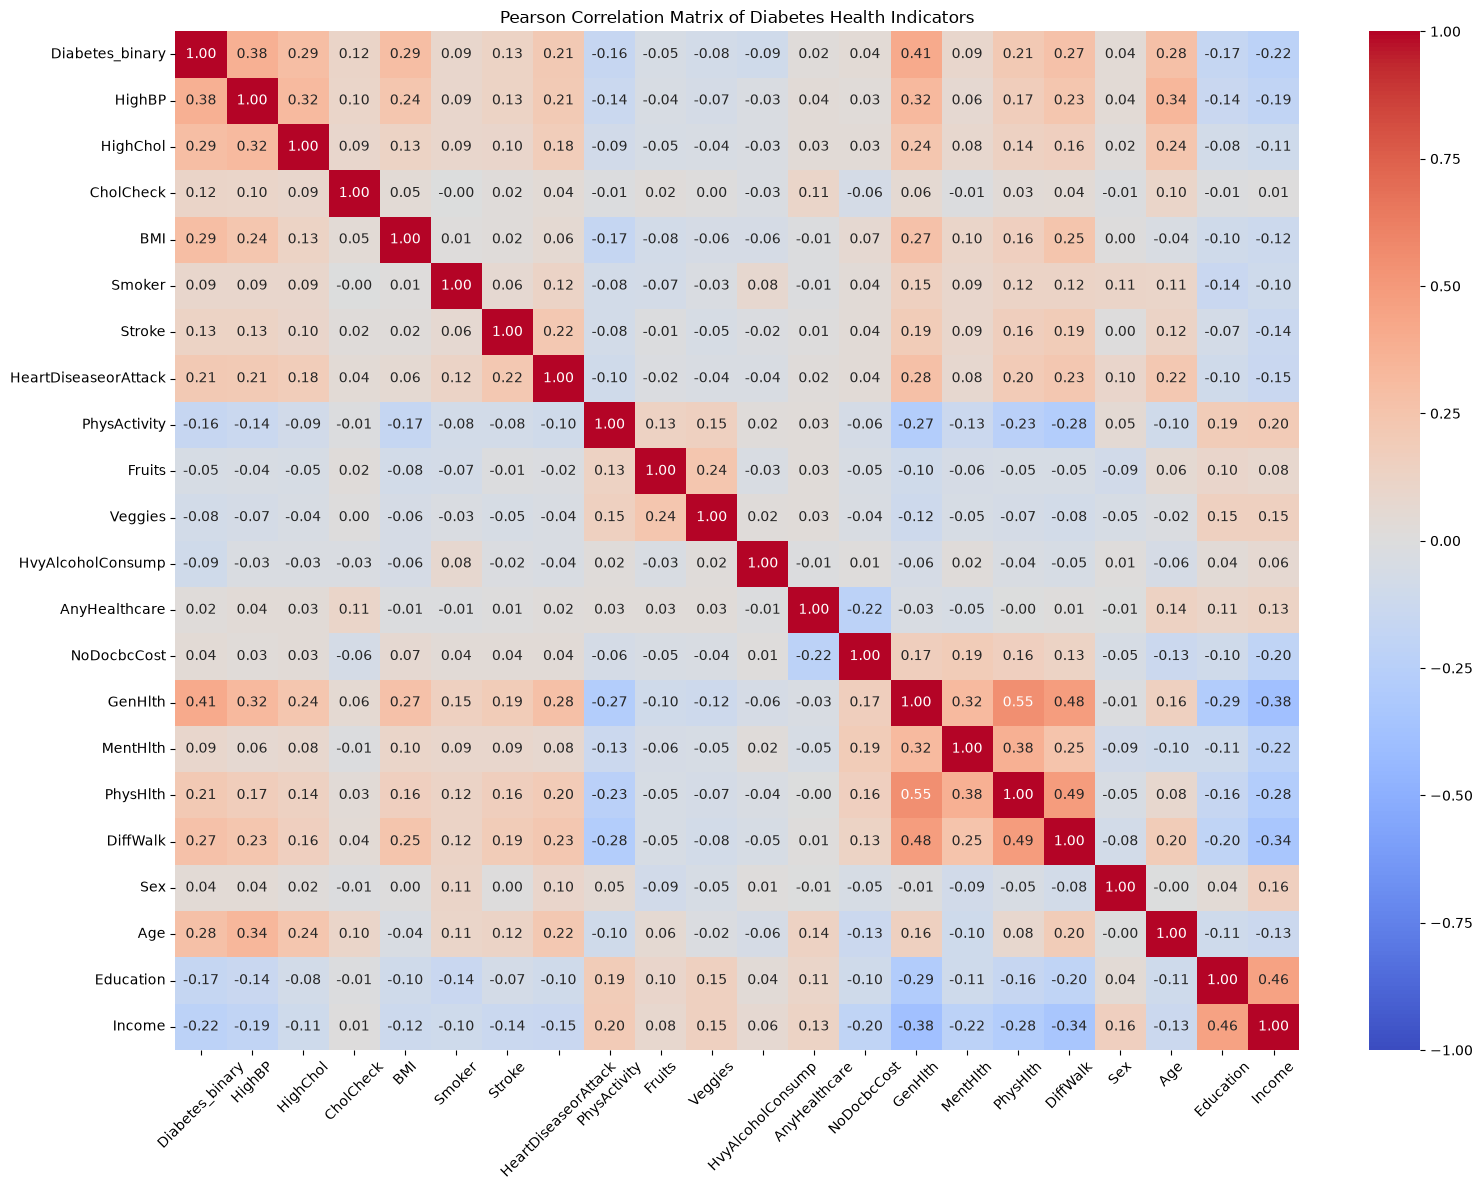

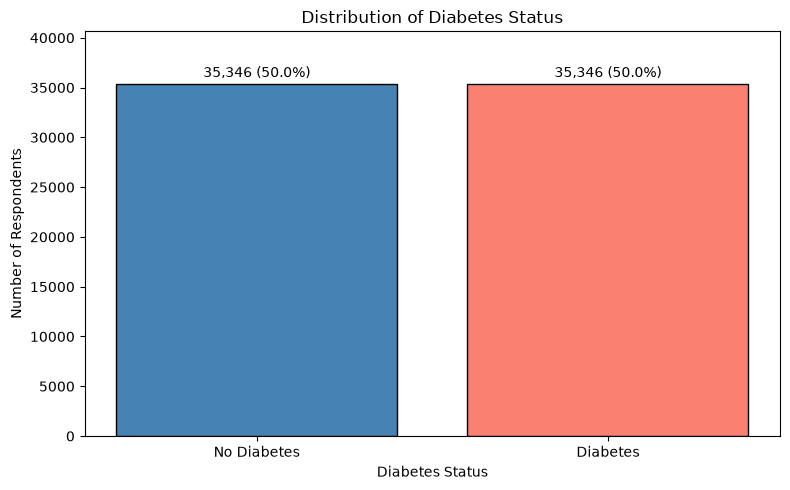

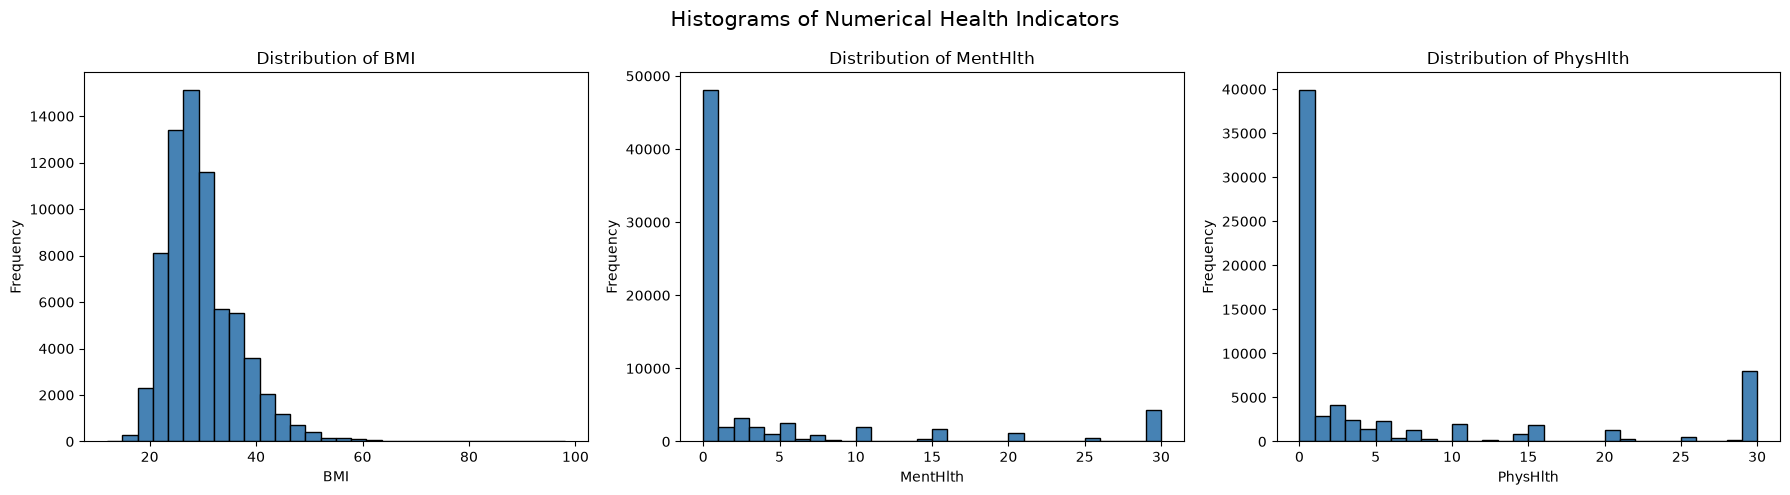

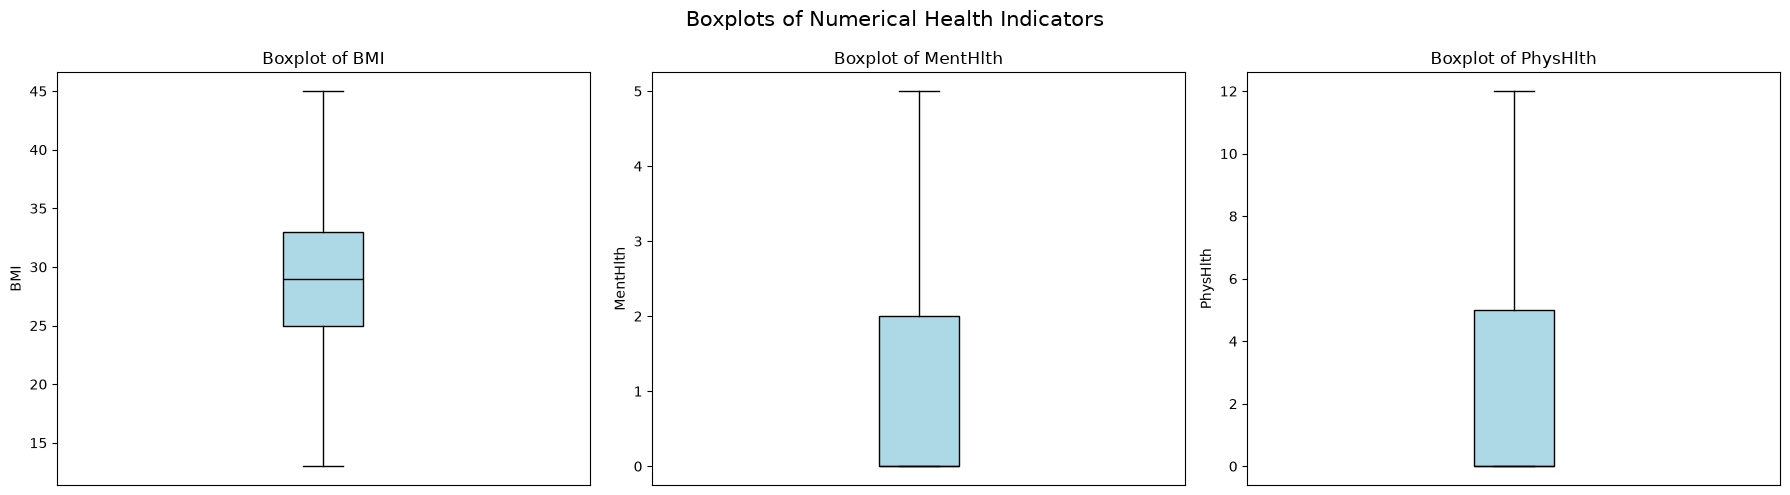


1-EXECUTOR WARM-UP RESULTS
--------------------------------
Rows: 70692
Columns: 22
Partitions: 2
Statistical Runtime: 5.594 seconds
Visualization Runtime: 2.383 seconds
Total Runtime: 7.977 seconds


In [44]:
# First warm-up run with one executor

warmup_1 = run_statistical_benchmark(
    num_executors=1,
    show_plots=True
)

print("\n1-EXECUTOR WARM-UP RESULTS")
print("--------------------------------")

print("Rows:", warmup_1["Rows"])
print("Columns:", warmup_1["Columns"])
print("Partitions:", warmup_1["Partitions"])

print(
    "Statistical Runtime:",
    round(warmup_1["Statistical_Runtime_s"], 3),
    "seconds"
)

print(
    "Visualization Runtime:",
    round(warmup_1["Visualization_Runtime_s"], 3),
    "seconds"
)

print(
    "Total Runtime:",
    round(warmup_1["Runtime_seconds"], 3),
    "seconds"
)

In [45]:
# Store the results of the 1-executor experiment
results_1_executor = []

# Repeat the statistical analysis three times
for run in range(1, 4):

    result = run_statistical_benchmark(
        num_executors=1,
        show_plots=False
    )

    result["Run"] = run
    results_1_executor.append(result)

    print(
        f"Run {run}: "
        f"{result['Runtime_seconds']:.3f} seconds"
    )

Run 1: 8.165 seconds
Run 2: 7.825 seconds
Run 3: 7.790 seconds


In [46]:
import pandas as pd

# Convert benchmark results into a table
results_1_df = pd.DataFrame(results_1_executor)

# Select the columns to display
results_1_df = results_1_df[
    [
        "Run",
        "Executors",
        "Runtime_seconds",
        "Statistical_Runtime_s",
        "Visualization_Runtime_s",
        "Partitions",
        "CPU_count",
        "Available_RAM_GB"
    ]
]

# Display results rounded to 3 decimal places
display(results_1_df.round(3))

,Run,Executors,Runtime_seconds,Statistical_Runtime_s,Visualization_Runtime_s,Partitions,CPU_count,Available_RAM_GB
0,1,1,8.165,6.549,1.616,2,16,1.198
1,2,1,7.825,6.110,1.715,2,16,1.131
2,3,1,7.790,6.062,1.727,2,16,1.000


In [47]:
mean_runtime_1 = results_1_df["Runtime_seconds"].mean()
std_runtime_1 = results_1_df["Runtime_seconds"].std()

print(f"Mean runtime: {mean_runtime_1:.3f} seconds")
print(f"Standard deviation: {std_runtime_1:.3f} seconds")

Mean runtime: 7.926 seconds
Standard deviation: 0.207 seconds


In [48]:
# Stop the current Spark application
try:
    spark.stop()
    print("Spark application stopped.")
except Exception as e:
    print("No active Spark application or it was already stopped.")

Spark application stopped.


In [49]:
# Import required libraries
import subprocess
import os
import signal
import time

# Check running Java processes
result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print("Before cleanup:")
print(result.stdout)

# Stop old Spark master and worker processes
for line in result.stdout.strip().splitlines():

    parts = line.split()

    # Skip lines without a valid process ID
    if len(parts) >= 2 and parts[0].isdigit():

        pid = int(parts[0])
        process_name = parts[1]

        if process_name in ["Master", "Worker"]:

            print(f"Stopping {process_name} PID {pid}")

            os.kill(pid, signal.SIGTERM)

# Allow processes to terminate
time.sleep(3)

Before cleanup:
68544 Jps
12692 Master
66856 SparkSubmit

Stopping Master PID 12692


In [50]:
# Start a fresh Spark Master for the 2-executor experiment

master_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1",
        "--port", "7077",
        "--webui-port", "8080"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(3)

print(
    "Master process running:",
    master_process.poll() is None
)

Master process running: True


In [51]:
# Start 2 Spark workers, each with 1 core

# Create an empty list to store worker processes
worker_processes = []

# Start two workers
for i in range(2):

    worker = subprocess.Popen(
        [
            SPARK_CLASS,
            "org.apache.spark.deploy.worker.Worker",
            "--cores", "1",
            "--memory", "2G",
            "--webui-port", str(8081 + i),
            "spark://127.0.0.1:7077"
        ],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )

    worker_processes.append(worker)

time.sleep(4)

# Check worker processes
for i, worker in enumerate(worker_processes, start=1):

    print(
        f"Worker {i} running:",
        worker.poll() is None
    )

Worker 1 running: True
Worker 2 running: True


In [52]:
from pyspark.sql import SparkSession

# Create a new Spark application
spark = (
    SparkSession.builder
    .appName("DiabetesStatisticalBenchmark_2Executors")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.executor.instances", "2")
    .config("spark.cores.max", "2")
    .getOrCreate()
)

print("Spark master:", spark.sparkContext.master)
print("Application ID:", spark.sparkContext.applicationId)

Spark master: spark://127.0.0.1:7077
Application ID: app-20261030055508-0000


In [53]:
result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print(result.stdout)

75940 Worker
66856 SparkSubmit
71640 CoarseGrainedExecutorBackend
24300 Worker
41692 Master
71324 CoarseGrainedExecutorBackend
72028 Jps



In [54]:
# Check active Spark executors
executor_info = (
    spark.sparkContext._jsc.sc()
    .statusTracker()
    .getExecutorInfos()
)

print("Executor entries:", len(executor_info))

for executor in executor_info:
    print(executor)

Executor entries: 3
org.apache.spark.SparkExecutorInfoImpl@2226cd81
org.apache.spark.SparkExecutorInfoImpl@3270a4d3
org.apache.spark.SparkExecutorInfoImpl@4e43f7fc



DESCRIPTIVE STATISTICS


,summary,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,count,70692,70692,70692,70692,70692,70692,70692,70692,70692,...,70692,70692,70692,70692,70692,70692,70692,70692,70692,70692
1,mean,0.5,0.5634583828438862,0.5257030498500538,0.975258869461891,29.856985231709388,0.4752730153341255,0.0621711084705483,0.1478102189781022,0.7030357041815198,...,0.9549595428054094,0.09391444576472585,2.837081989475471,3.7520370056017653,5.810417020313473,0.25273015334125504,0.4569965484071748,8.584054772817291,4.920952865953715,5.698310982855203
2,stddev,0.5000035365055782,0.49596019315986284,0.4993424480263351,0.15533624280406588,7.113953851576778,0.4993917341107828,0.24146777536770814,0.3549142713619424,0.4569239063509657,...,0.20739436554190965,0.2917117179591932,1.1135645170395425,8.155626553608043,10.062260531163895,0.43458059612338523,0.4981507939458703,2.8521531099513346,1.0290808004847722,2.1751959759183523
3,min,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,max,1.0,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0



DIABETES FREQUENCY DISTRIBUTION


,Diabetes_binary,Frequency,Percentage
0,0.0,35346,50.0
1,1.0,35346,50.0



BOXPLOT STATISTICS


,med,q1,q3,whislo,whishi,fliers
BMI,29.0,25.0,33.0,13.0,45.0,[]
MentHlth,0.0,0.0,2.0,0.0,5.0,[]
PhysHlth,0.0,0.0,5.0,0.0,12.0,[]



PEARSON CORRELATION WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


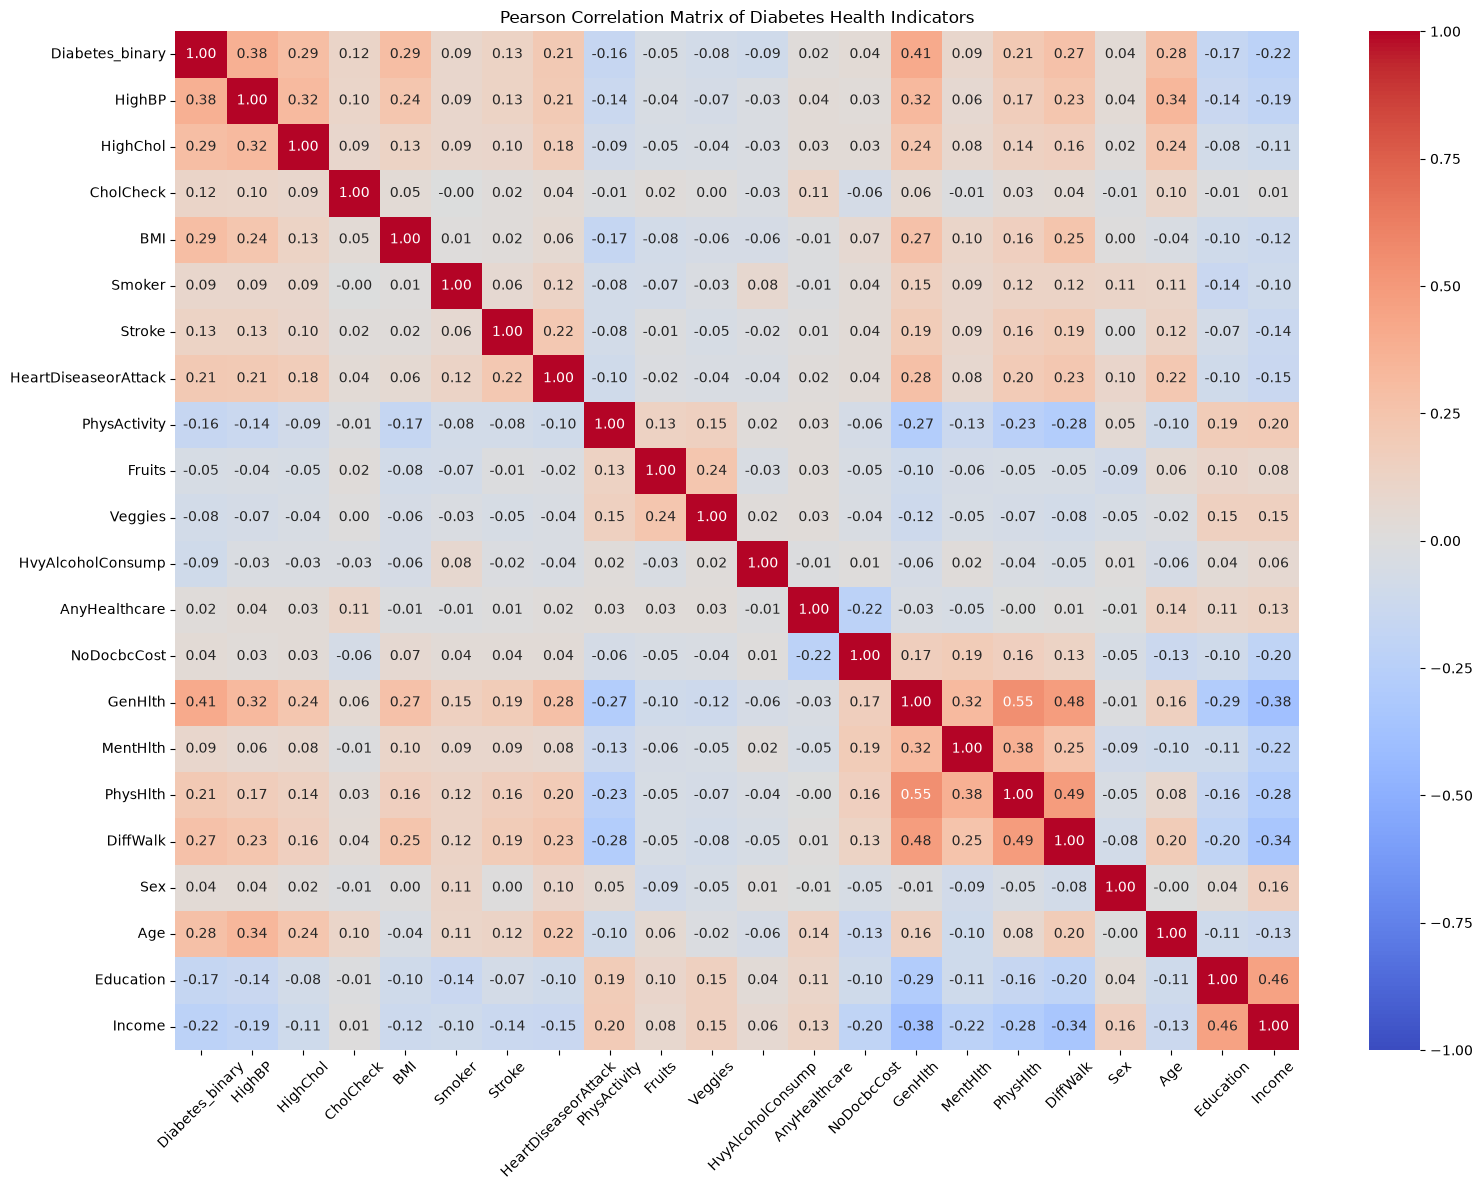

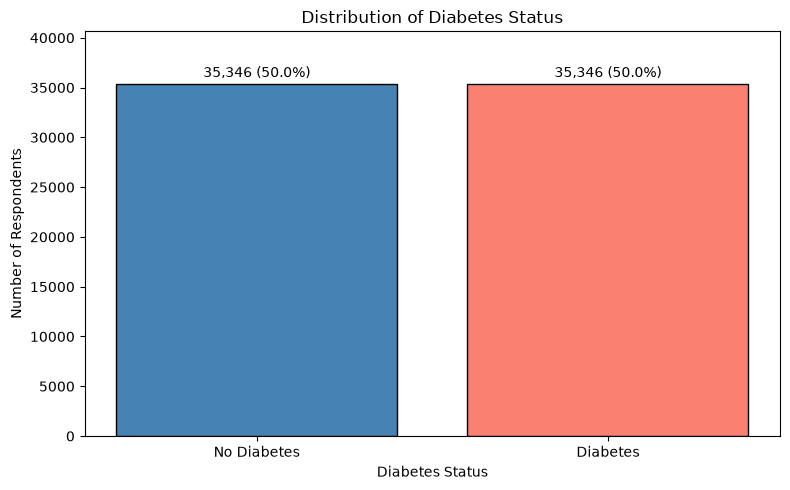

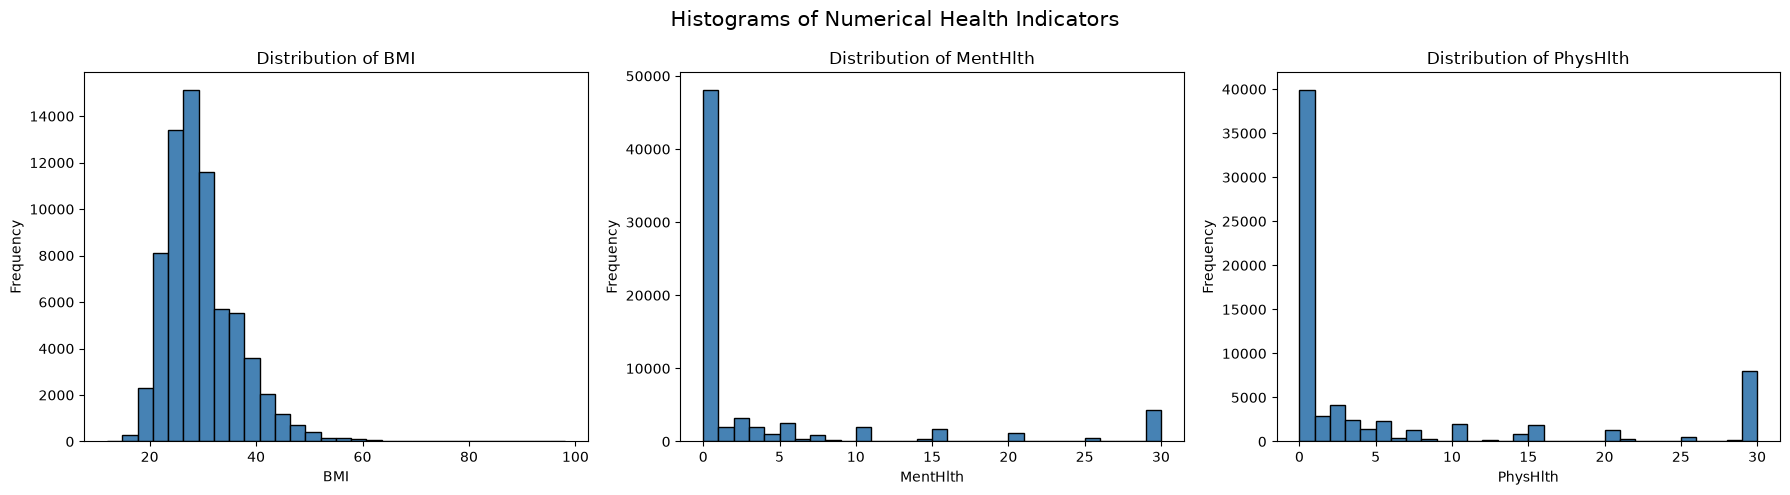

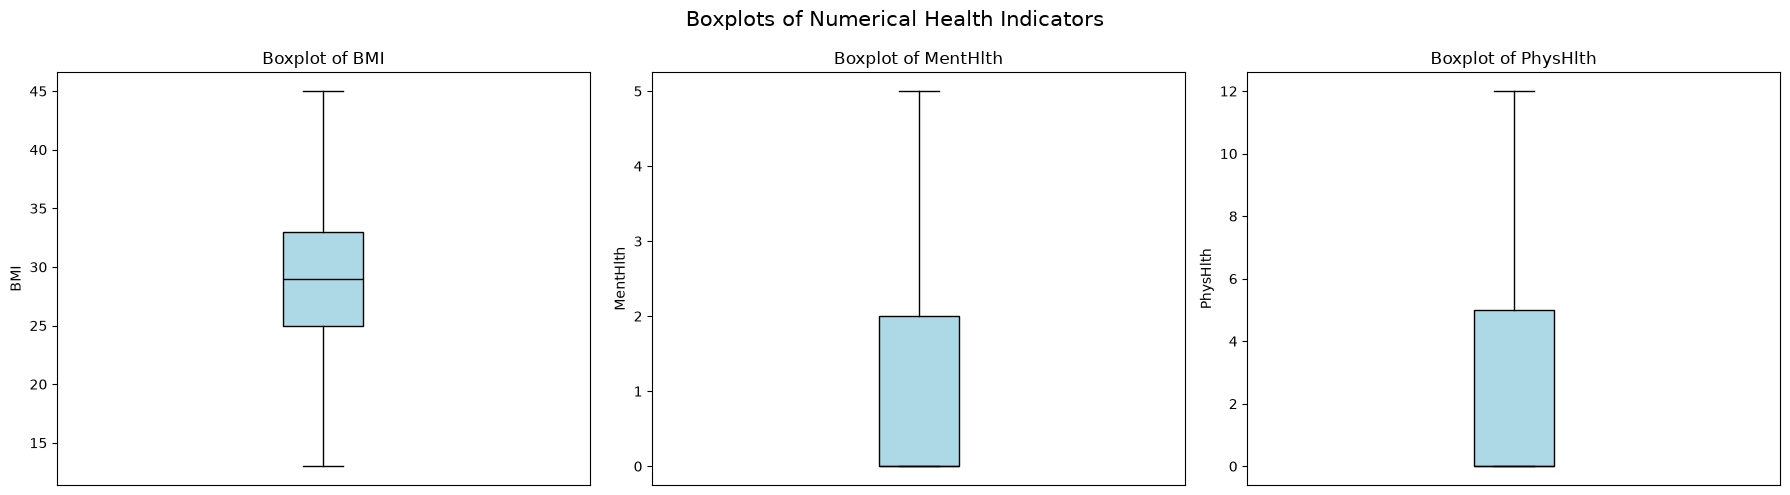

2-executor warm-up runtime: 28.386 seconds


In [55]:
# Warm-up run for 2 executors

warmup_2 = run_statistical_benchmark(
    num_executors=2
)

print(
    f"2-executor warm-up runtime: "
    f"{warmup_2['Runtime_seconds']:.3f} seconds"
)


DESCRIPTIVE STATISTICS


,summary,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,count,70692,70692,70692,70692,70692,70692,70692,70692,70692,...,70692,70692,70692,70692,70692,70692,70692,70692,70692,70692
1,mean,0.5,0.5634583828438862,0.5257030498500538,0.975258869461891,29.856985231709388,0.4752730153341255,0.0621711084705483,0.1478102189781022,0.7030357041815198,...,0.9549595428054094,0.09391444576472585,2.837081989475471,3.7520370056017653,5.810417020313473,0.25273015334125504,0.4569965484071748,8.584054772817291,4.920952865953715,5.698310982855203
2,stddev,0.5000035365055782,0.49596019315986284,0.4993424480263351,0.15533624280406588,7.113953851576778,0.4993917341107828,0.24146777536770814,0.3549142713619424,0.4569239063509657,...,0.20739436554190965,0.2917117179591932,1.1135645170395425,8.155626553608043,10.062260531163895,0.43458059612338523,0.4981507939458703,2.8521531099513346,1.0290808004847722,2.1751959759183523
3,min,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,max,1.0,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0



DIABETES FREQUENCY DISTRIBUTION


,Diabetes_binary,Frequency,Percentage
0,0.0,35346,50.0
1,1.0,35346,50.0



BOXPLOT STATISTICS


,med,q1,q3,whislo,whishi,fliers
BMI,29.0,25.0,33.0,13.0,45.0,[]
MentHlth,0.0,0.0,2.0,0.0,5.0,[]
PhysHlth,0.0,0.0,5.0,0.0,12.0,[]



PEARSON CORRELATION WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


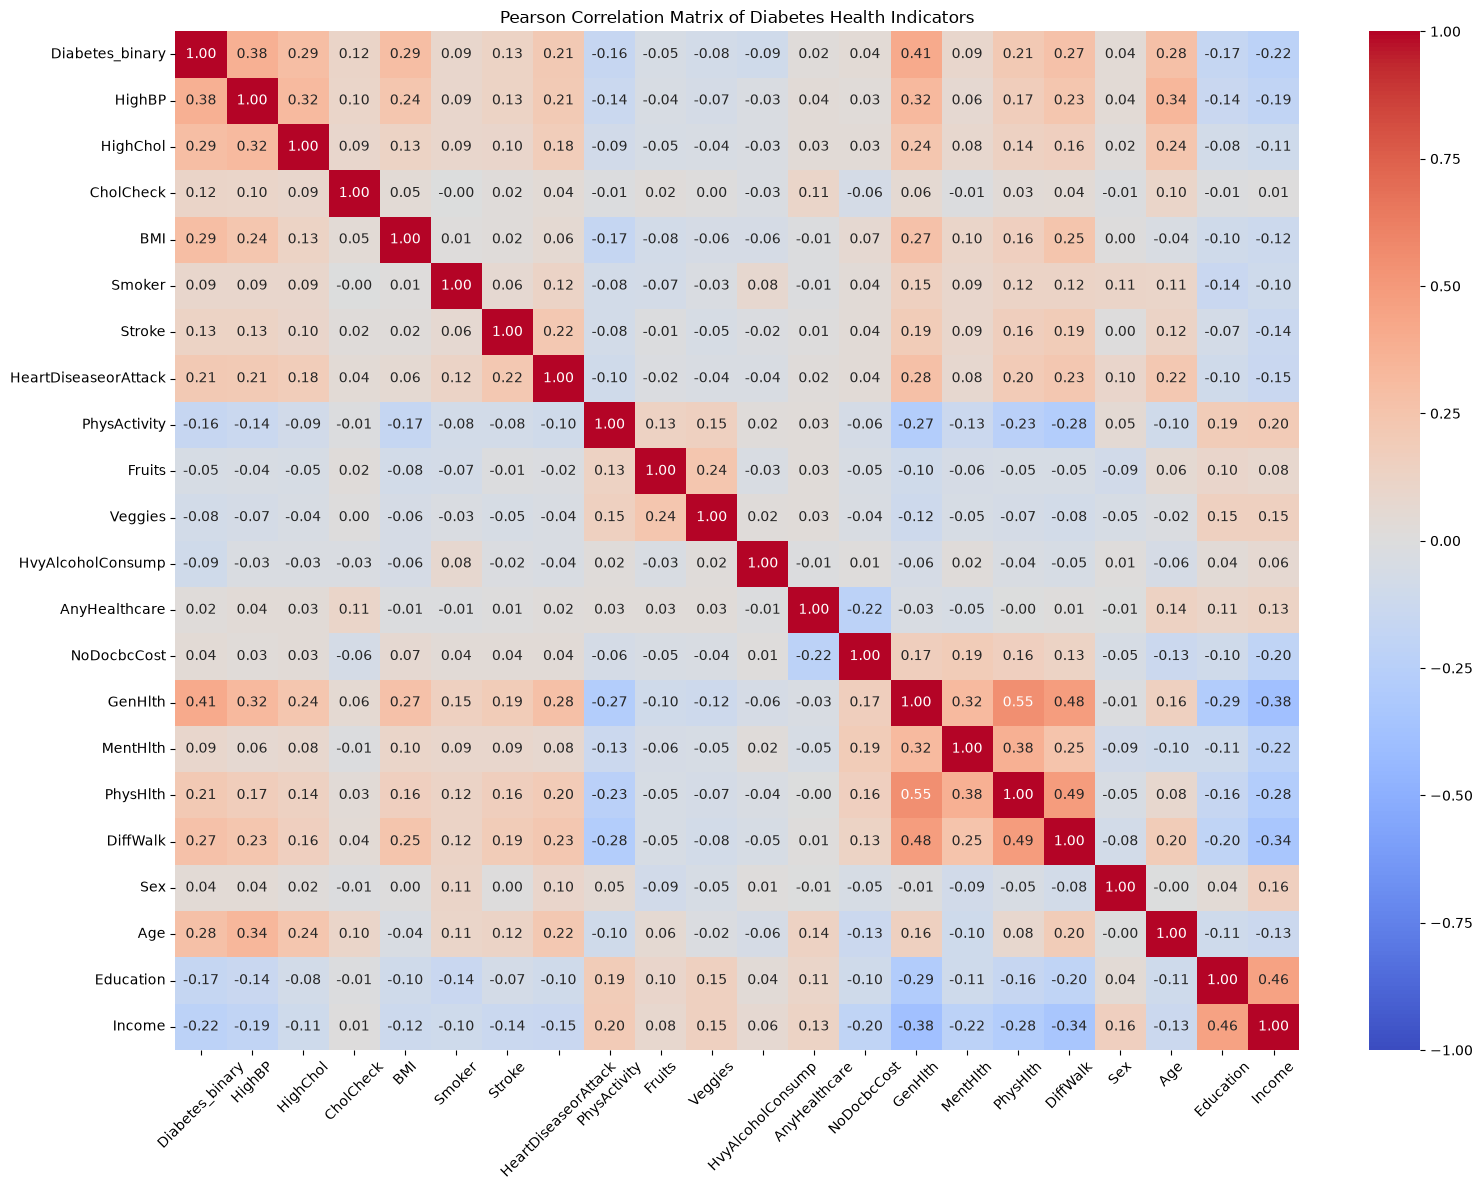

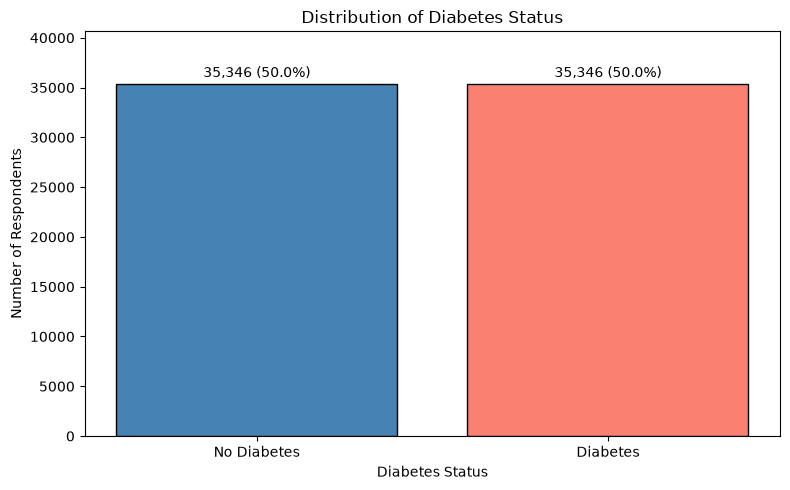

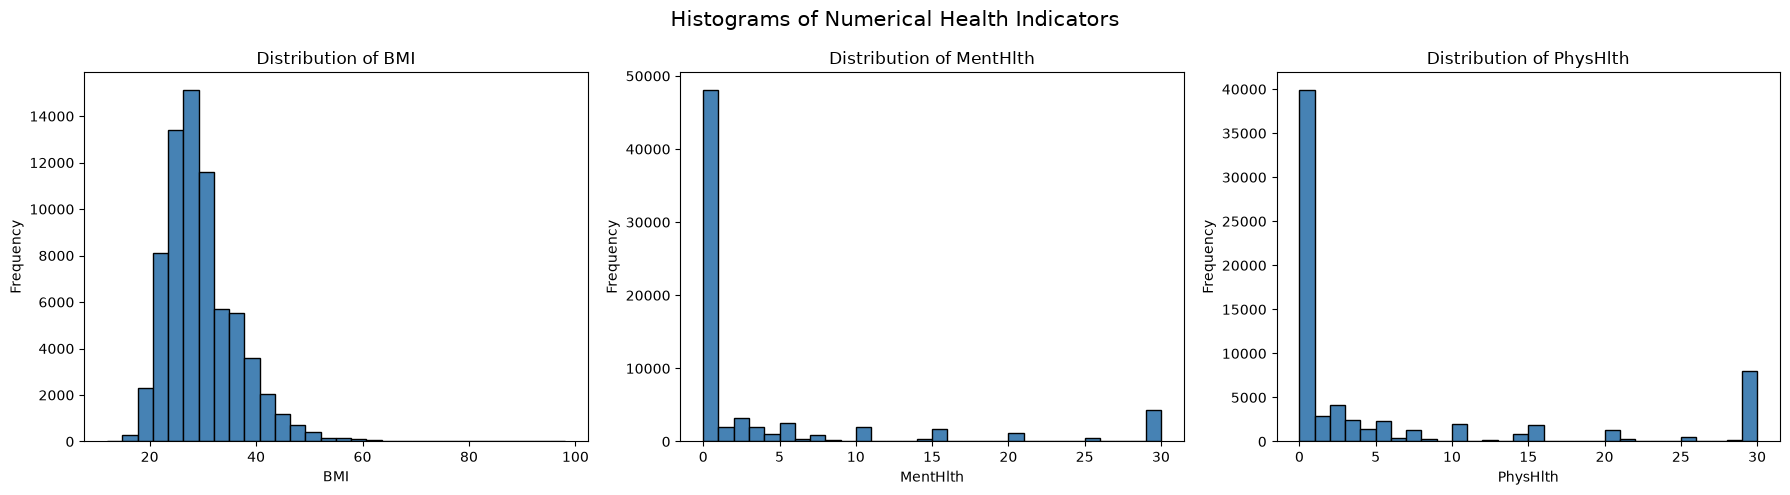

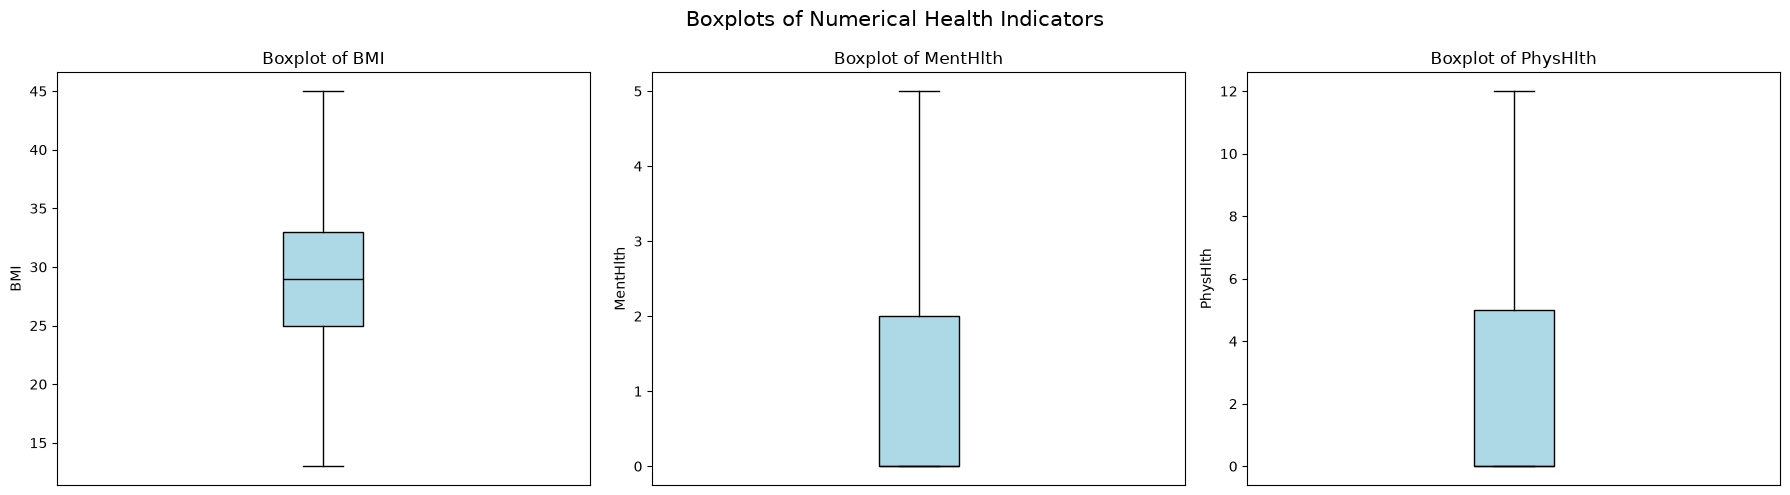

Run 1: 8.855 seconds

DESCRIPTIVE STATISTICS


,summary,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,count,70692,70692,70692,70692,70692,70692,70692,70692,70692,...,70692,70692,70692,70692,70692,70692,70692,70692,70692,70692
1,mean,0.5,0.5634583828438862,0.5257030498500538,0.975258869461891,29.856985231709388,0.4752730153341255,0.0621711084705483,0.1478102189781022,0.7030357041815198,...,0.9549595428054094,0.09391444576472585,2.837081989475471,3.7520370056017653,5.810417020313473,0.25273015334125504,0.4569965484071748,8.584054772817291,4.920952865953715,5.698310982855203
2,stddev,0.5000035365055782,0.49596019315986284,0.4993424480263351,0.15533624280406588,7.113953851576778,0.4993917341107828,0.24146777536770814,0.3549142713619424,0.4569239063509657,...,0.20739436554190968,0.2917117179591932,1.1135645170395425,8.155626553608043,10.062260531163895,0.43458059612338523,0.4981507939458703,2.8521531099513346,1.0290808004847722,2.1751959759183523
3,min,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,max,1.0,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0



DIABETES FREQUENCY DISTRIBUTION


,Diabetes_binary,Frequency,Percentage
0,0.0,35346,50.0
1,1.0,35346,50.0



BOXPLOT STATISTICS


,med,q1,q3,whislo,whishi,fliers
BMI,29.0,25.0,33.0,13.0,45.0,[]
MentHlth,0.0,0.0,2.0,0.0,5.0,[]
PhysHlth,0.0,0.0,5.0,0.0,12.0,[]



PEARSON CORRELATION WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


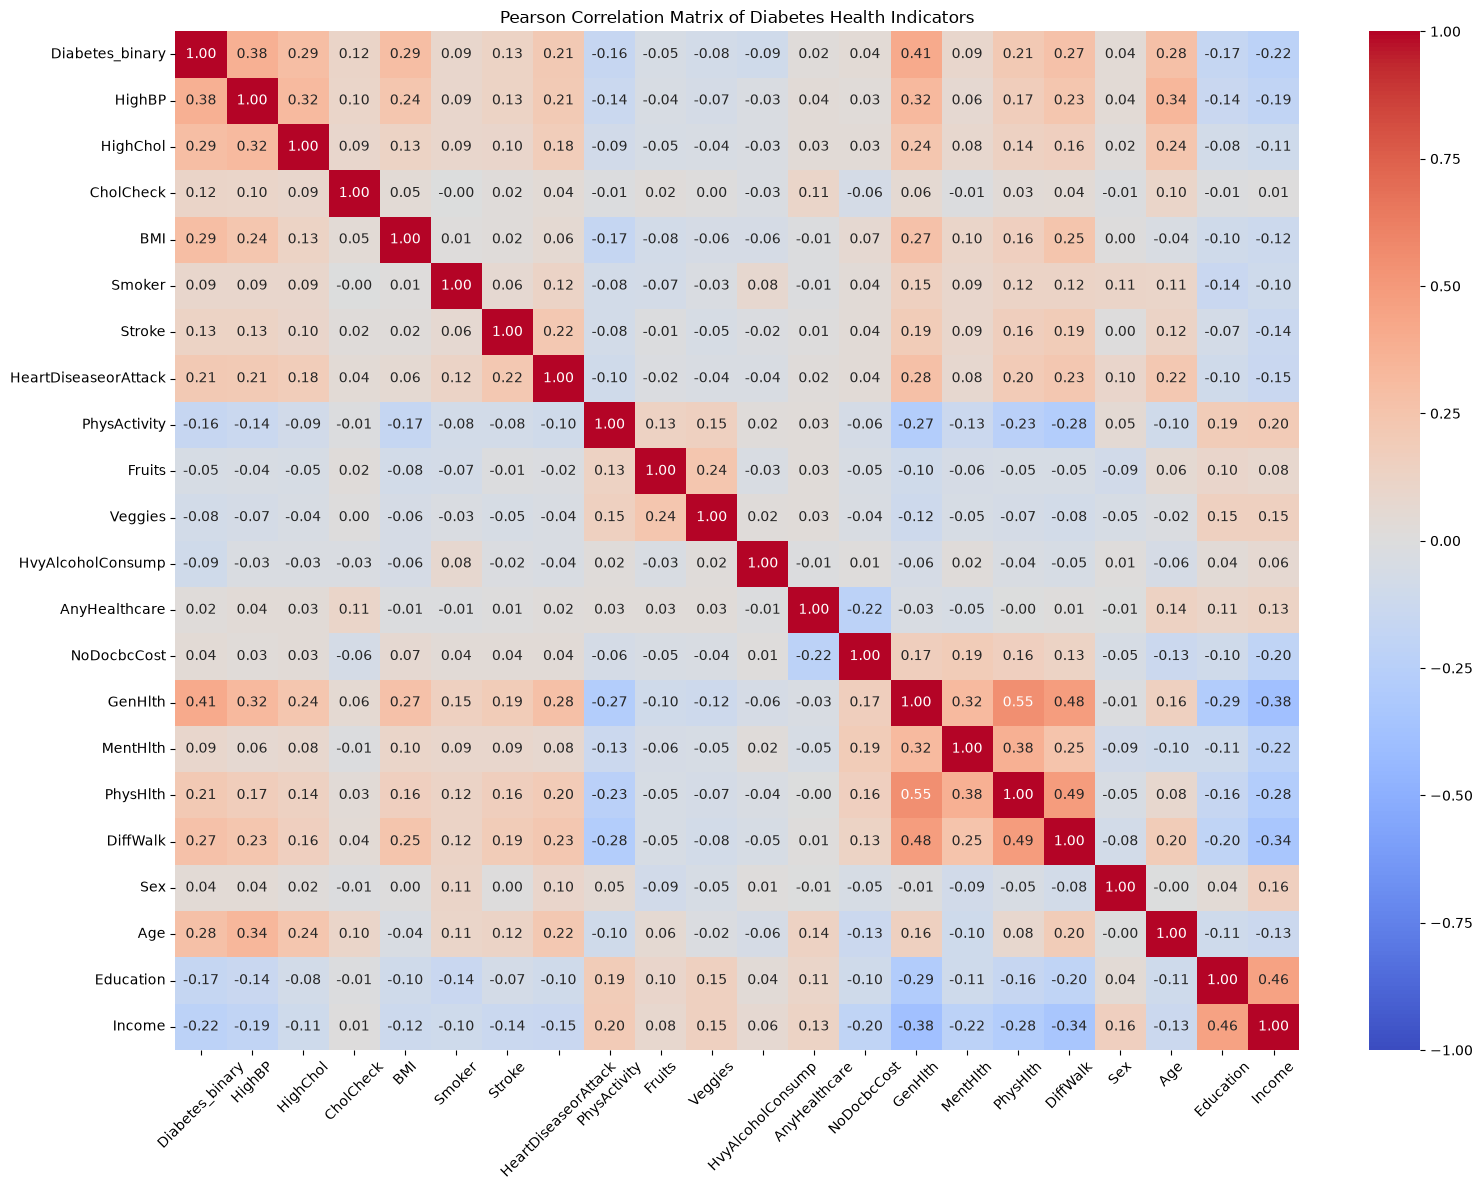

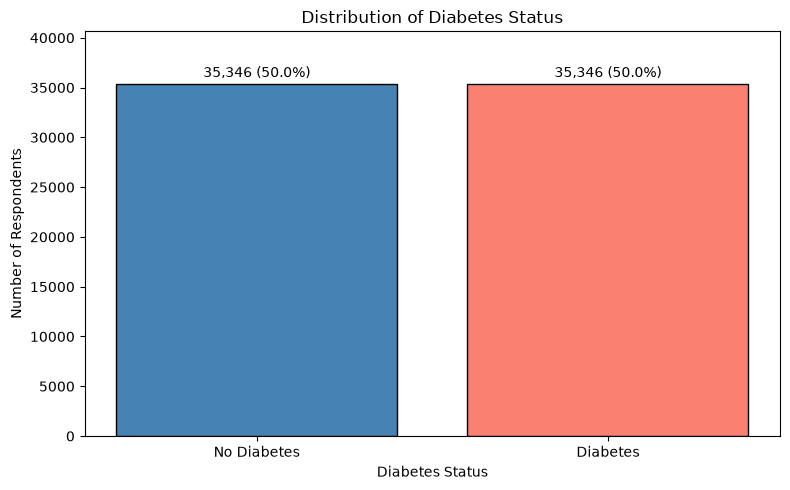

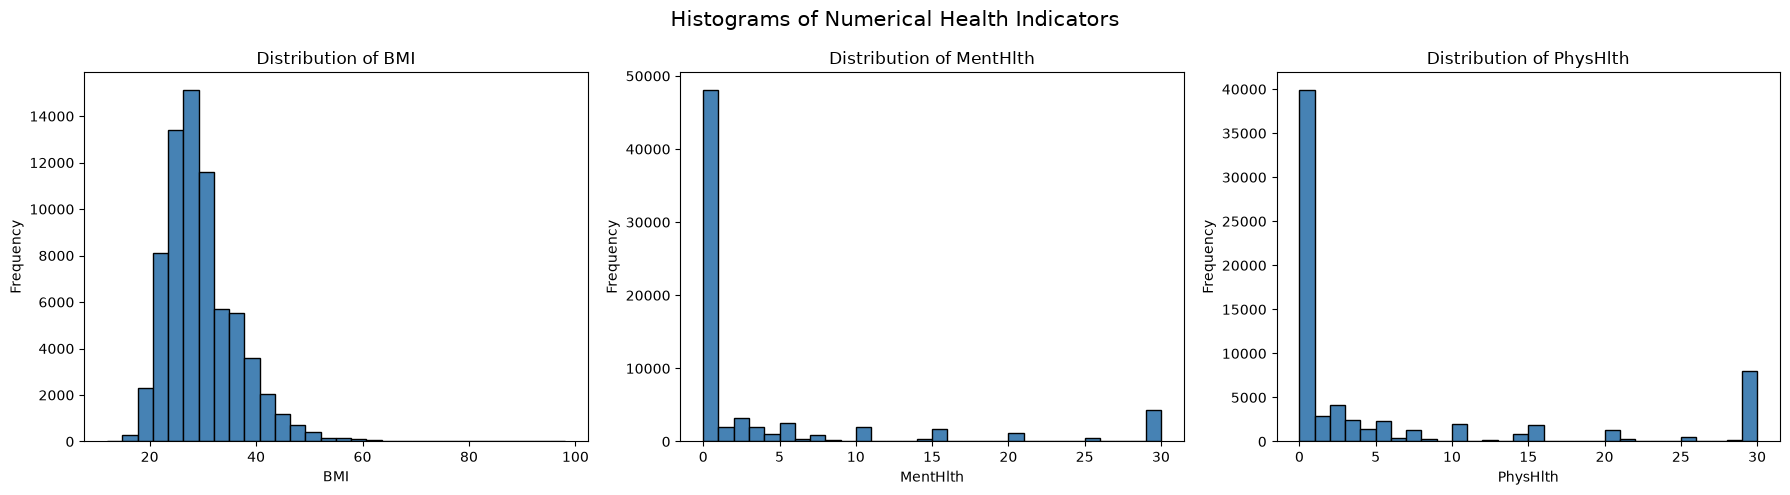

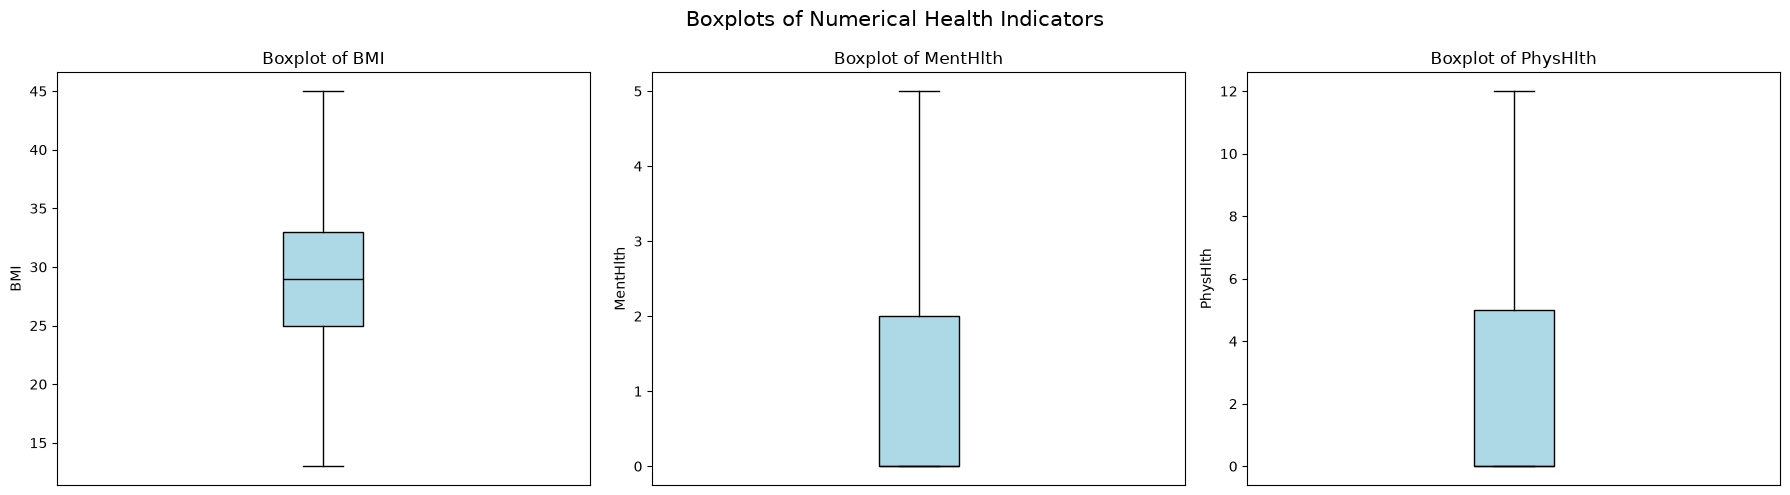

Run 2: 7.917 seconds

DESCRIPTIVE STATISTICS


,summary,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,count,70692,70692,70692,70692,70692,70692,70692,70692,70692,...,70692,70692,70692,70692,70692,70692,70692,70692,70692,70692
1,mean,0.5,0.5634583828438862,0.5257030498500538,0.975258869461891,29.856985231709388,0.4752730153341255,0.0621711084705483,0.1478102189781022,0.7030357041815198,...,0.9549595428054094,0.09391444576472585,2.837081989475471,3.7520370056017653,5.810417020313473,0.25273015334125504,0.4569965484071748,8.584054772817291,4.920952865953715,5.698310982855203
2,stddev,0.5000035365055782,0.49596019315986284,0.4993424480263351,0.15533624280406588,7.113953851576778,0.4993917341107828,0.24146777536770814,0.3549142713619424,0.4569239063509657,...,0.20739436554190968,0.2917117179591932,1.1135645170395425,8.155626553608043,10.062260531163895,0.43458059612338523,0.4981507939458703,2.8521531099513346,1.0290808004847722,2.1751959759183523
3,min,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,max,1.0,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0



DIABETES FREQUENCY DISTRIBUTION


,Diabetes_binary,Frequency,Percentage
0,0.0,35346,50.0
1,1.0,35346,50.0



BOXPLOT STATISTICS


,med,q1,q3,whislo,whishi,fliers
BMI,29.0,25.0,33.0,13.0,45.0,[]
MentHlth,0.0,0.0,2.0,0.0,5.0,[]
PhysHlth,0.0,0.0,5.0,0.0,12.0,[]



PEARSON CORRELATION WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


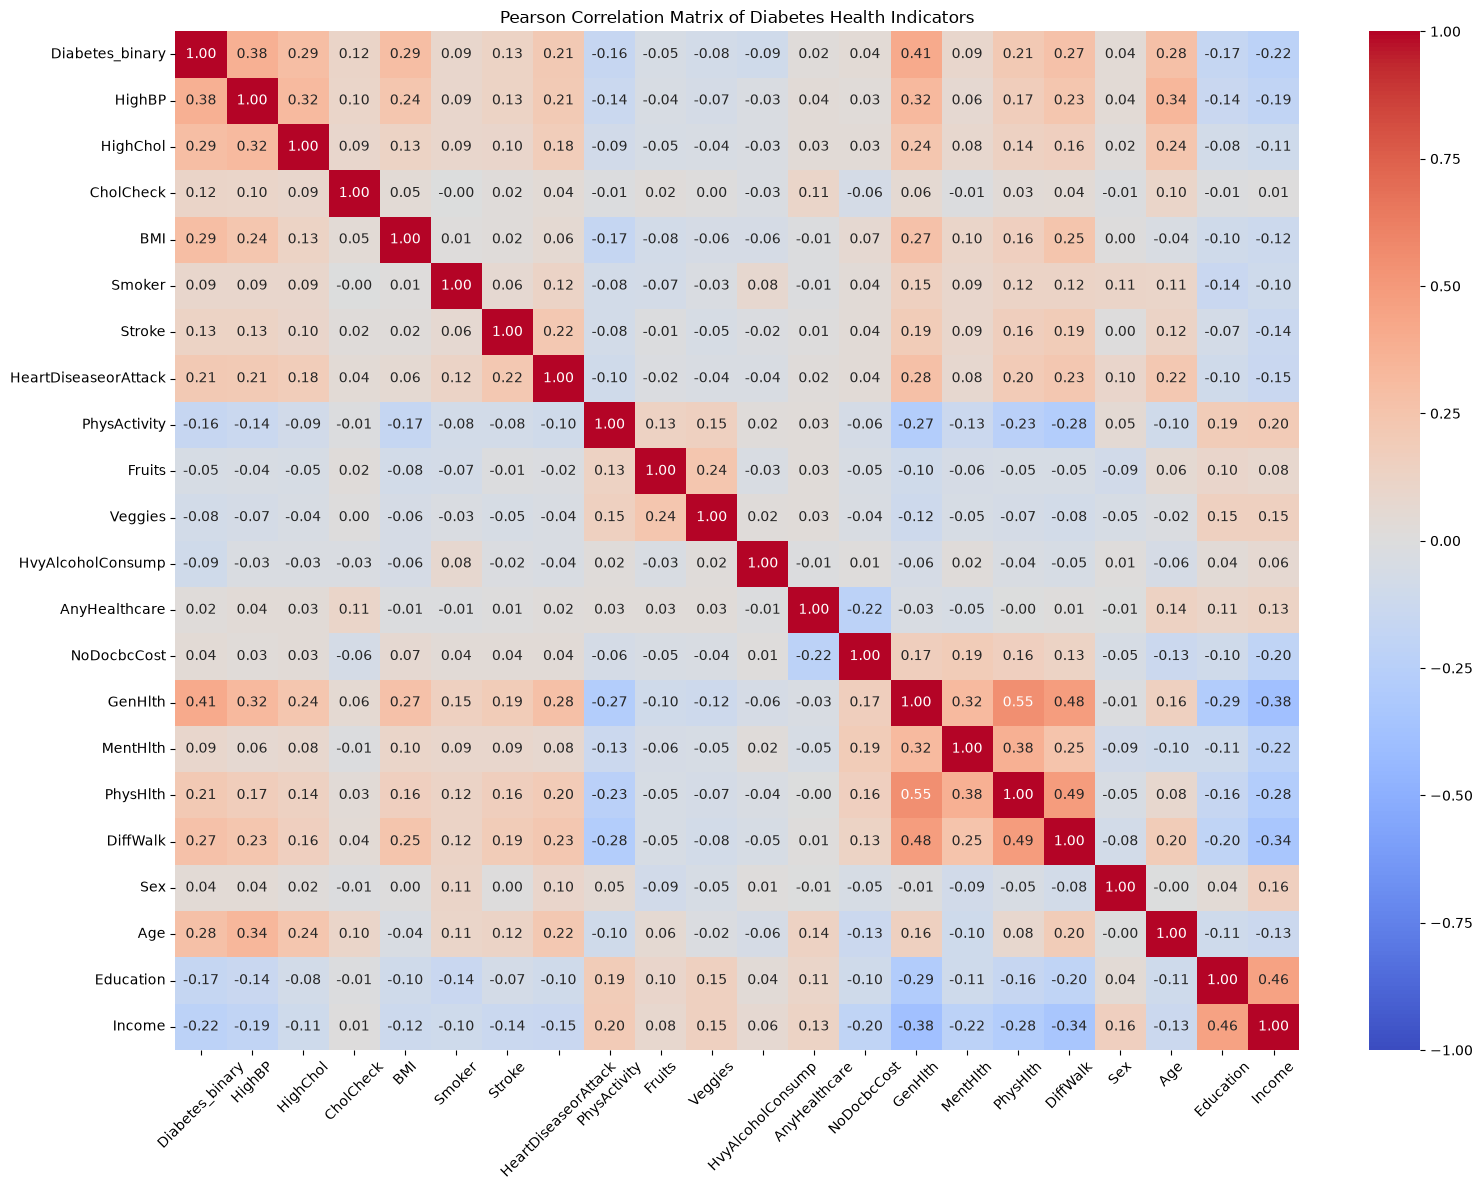

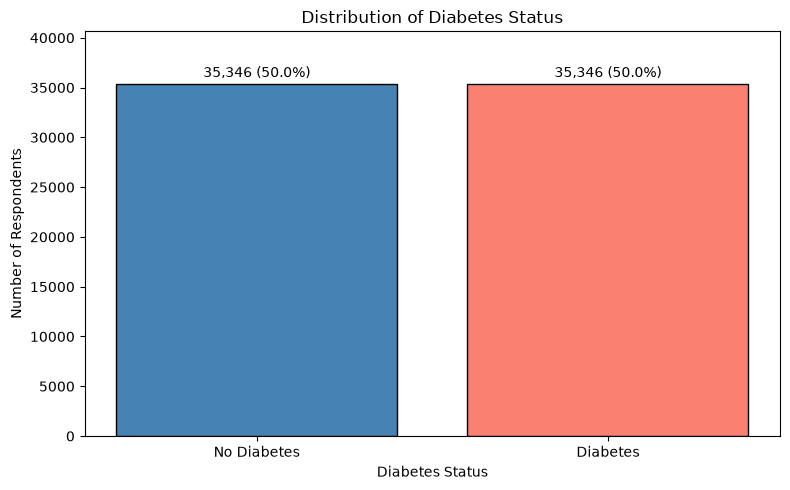

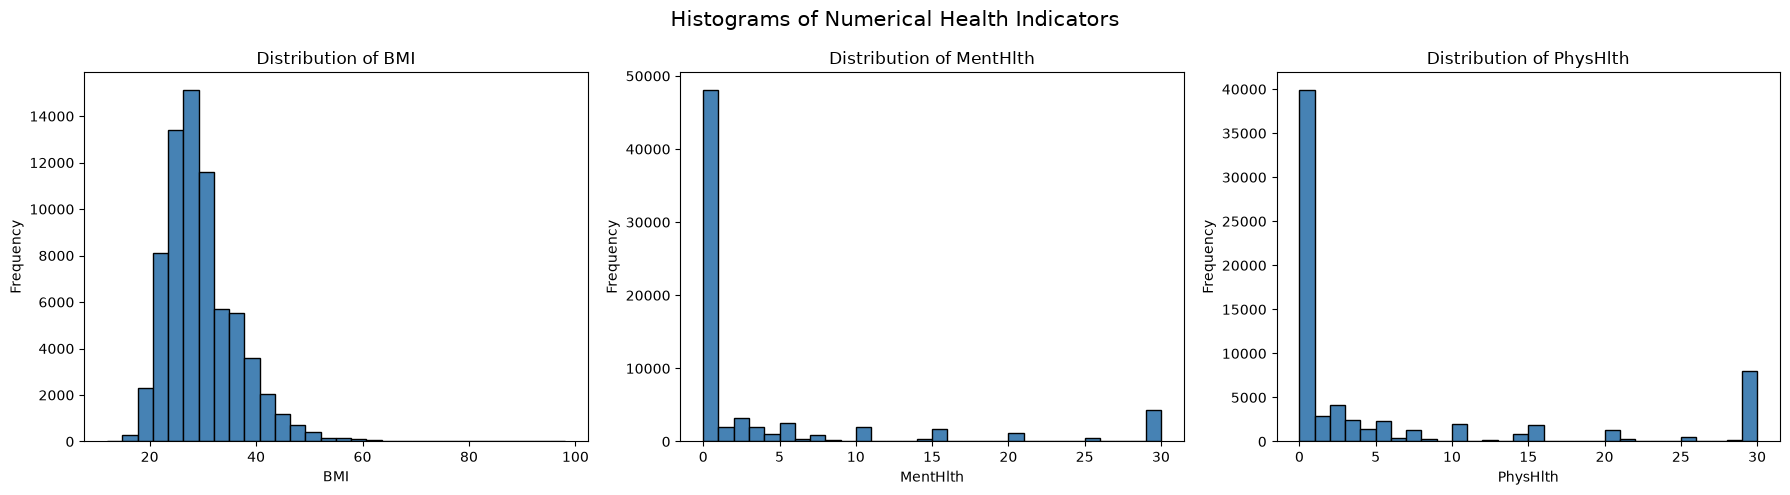

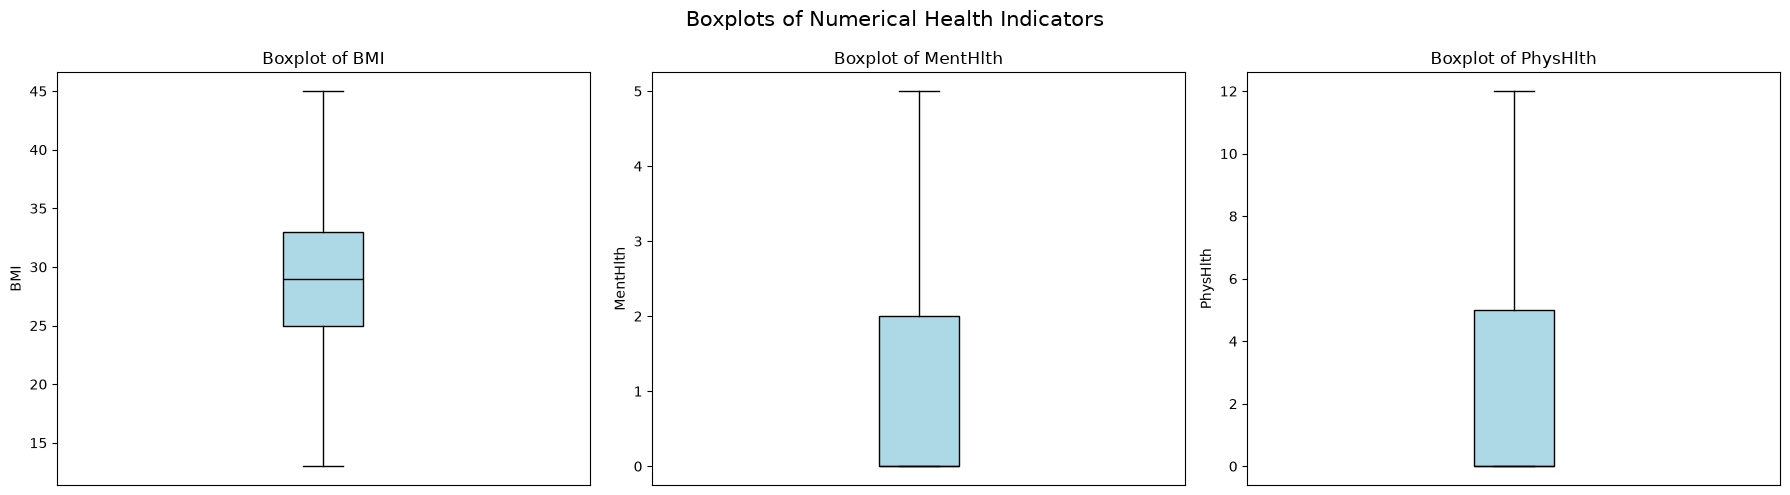

Run 3: 9.318 seconds


In [56]:
results_2_executor = []

for run in range(1, 4):

    result = run_statistical_benchmark(num_executors=2)

    result["Run"] = run
    results_2_executor.append(result)

    print(
        f"Run {run}: "
        f"{result['Runtime_seconds']:.3f} seconds"
    )

In [57]:
results_2_df = pd.DataFrame(results_2_executor)

results_2_df = results_2_df[
    [
        "Run",
        "Executors",
        "Runtime_seconds",
        "Partitions",
        "CPU_count",
        "Available_RAM_GB"
    ]
]

results_2_df

,Run,Executors,Runtime_seconds,Partitions,CPU_count,Available_RAM_GB
0,1,2,8.855315,2,16,0.698044
1,2,2,7.917455,2,16,0.660892
2,3,2,9.317813,2,16,0.974659


In [58]:
mean_runtime_2 = results_2_df["Runtime_seconds"].mean()
std_runtime_2 = results_2_df["Runtime_seconds"].std()

print(f"Mean runtime: {mean_runtime_2:.3f} seconds")
print(f"Standard deviation: {std_runtime_2:.3f} seconds")

Mean runtime: 8.697 seconds
Standard deviation: 0.713 seconds


In [59]:
# Before moving to 4 executors, compare the
# statistical experiments with 1 and 2 executors

comparison_df = pd.DataFrame({
    "Executors": [1, 2],
    "Mean_Runtime_s": [
        results_1_df["Runtime_seconds"].mean(),
        results_2_df["Runtime_seconds"].mean()
    ],
    "Std_Runtime_s": [
        results_1_df["Runtime_seconds"].std(),
        results_2_df["Runtime_seconds"].std()
    ]
})

comparison_df["Speedup"] = (
    comparison_df.loc[
        comparison_df["Executors"] == 1,
        "Mean_Runtime_s"
    ].iloc[0]
    / comparison_df["Mean_Runtime_s"]
)

comparison_df


,Executors,Mean_Runtime_s,Std_Runtime_s,Speedup
0,1,7.926497,0.207409,1.00000
1,2,8.696861,0.713499,0.91142


Mean-run time vs executors


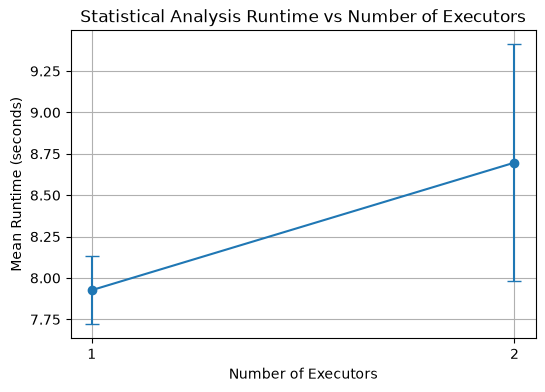

In [60]:
plt.figure(figsize=(6,4))

plt.errorbar(
    comparison_df["Executors"],
    comparison_df["Mean_Runtime_s"],
    yerr=comparison_df["Std_Runtime_s"],
    marker="o",
    capsize=5
)

plt.xlabel("Number of Executors")
plt.ylabel("Mean Runtime (seconds)")
plt.title("Statistical Analysis Runtime vs Number of Executors")
plt.xticks([1, 2])
plt.grid(True)
plt.show()

### Speed-up Plot

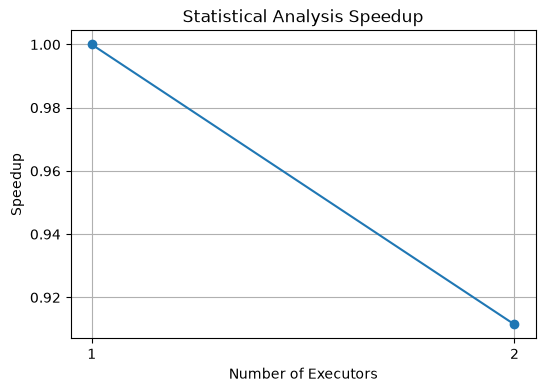

In [61]:
plt.figure(figsize=(6,4))

plt.plot(
    comparison_df["Executors"],
    comparison_df["Speedup"],
    marker="o"
)

plt.xlabel("Number of Executors")
plt.ylabel("Speedup")
plt.title("Statistical Analysis Speedup")
plt.xticks([1, 2])
plt.grid(True)
plt.show()

In [62]:
# Repeat the statistical analysis experiment with 4 executors,
# one core each.

# Stop Spark application
try:
    spark.stop()
    print("Spark application stopped.")
except Exception as e:
    print("No active Spark application or it was already stopped.")

Spark application stopped.


In [63]:
# Cleanup loop to stop the old Spark master and workers

import subprocess
import os
import signal
import time

result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print("Before cleanup:")
print(result.stdout)

for line in result.stdout.strip().splitlines():
    parts = line.split()

    # Skip warning lines or anything without a numeric PID
    if len(parts) >= 2 and parts[0].isdigit():

        pid = int(parts[0])
        process_name = parts[1]

        if process_name in ["Master", "Worker"]:
            print(f"Stopping {process_name} PID {pid}")
            os.kill(pid, signal.SIGTERM)

time.sleep(3)

Before cleanup:
75940 Worker
66856 SparkSubmit
24300 Worker
41692 Master
66348 Jps

Stopping Worker PID 75940
Stopping Worker PID 24300
Stopping Master PID 41692


In [64]:
# Start a fresh Spark Master for the 4-executor
# statistical analysis experiment

master_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1",
        "--port", "7077",
        "--webui-port", "8080"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(3)

print("Master process running:", master_process.poll() is None)

Master process running: True


In [65]:
# Start 4 Spark workers, each with 1 core

# Create an empty list to save the workers
worker_processes_4 = []

# Create four workers with different web UI ports
for i in range(4):

    worker = subprocess.Popen(
        [
            SPARK_CLASS,
            "org.apache.spark.deploy.worker.Worker",
            "--cores", "1",
            "--memory", "2G",
            "--webui-port", str(8081 + i),
            "spark://127.0.0.1:7077"
        ],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )

    worker_processes_4.append(worker)

time.sleep(6)

for i, worker in enumerate(worker_processes_4, start=1):

    print(
        f"Worker {i} running:",
        worker.poll() is None
    )

Worker 1 running: True
Worker 2 running: True
Worker 3 running: True
Worker 4 running: True


In [66]:
from pyspark.sql import SparkSession

# Reconnect Spark to the four 1-core workers

spark = (
    SparkSession.builder
    .appName("DiabetesStatisticalBenchmark")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.executor.instances", "4")
    .config("spark.cores.max", "4")
    .getOrCreate()
)

print("Spark master:", spark.sparkContext.master)
print("Application ID:", spark.sparkContext.applicationId)

Spark master: spark://127.0.0.1:7077
Application ID: app-20261030060301-0000


In [67]:
# Verify Java processes

result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print(result.stdout)


67408 CoarseGrainedExecutorBackend
73620 Worker
73684 CoarseGrainedExecutorBackend
76100 CoarseGrainedExecutorBackend
76516 Worker
15160 Jps
62776 CoarseGrainedExecutorBackend
66856 SparkSubmit
72216 Master
77352 Worker
70108 Worker




DESCRIPTIVE STATISTICS


,summary,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,count,70692,70692,70692,70692,70692,70692,70692,70692,70692,...,70692,70692,70692,70692,70692,70692,70692,70692,70692,70692
1,mean,0.5,0.5634583828438862,0.5257030498500538,0.975258869461891,29.856985231709388,0.4752730153341255,0.0621711084705483,0.1478102189781022,0.7030357041815198,...,0.9549595428054094,0.09391444576472585,2.837081989475471,3.7520370056017653,5.810417020313473,0.25273015334125504,0.4569965484071748,8.584054772817291,4.920952865953715,5.698310982855203
2,stddev,0.500003536505579,0.49596019315986284,0.4993424480263366,0.1553362428040657,7.113953851576819,0.4993917341107826,0.2414677753677074,0.354914271361942,0.456923906350966,...,0.2073943655419098,0.2917117179591919,1.1135645170395423,8.155626553608052,10.06226053116388,0.4345805961233848,0.4981507939458711,2.852153109951339,1.029080800484773,2.175195975918353
3,min,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,max,1.0,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0



DIABETES FREQUENCY DISTRIBUTION


,Diabetes_binary,Frequency,Percentage
0,0.0,35346,50.0
1,1.0,35346,50.0



BOXPLOT STATISTICS


,med,q1,q3,whislo,whishi,fliers
BMI,29.0,25.0,33.0,13.0,45.0,[]
MentHlth,0.0,0.0,2.0,0.0,5.0,[]
PhysHlth,0.0,0.0,5.0,0.0,12.0,[]



PEARSON CORRELATION WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


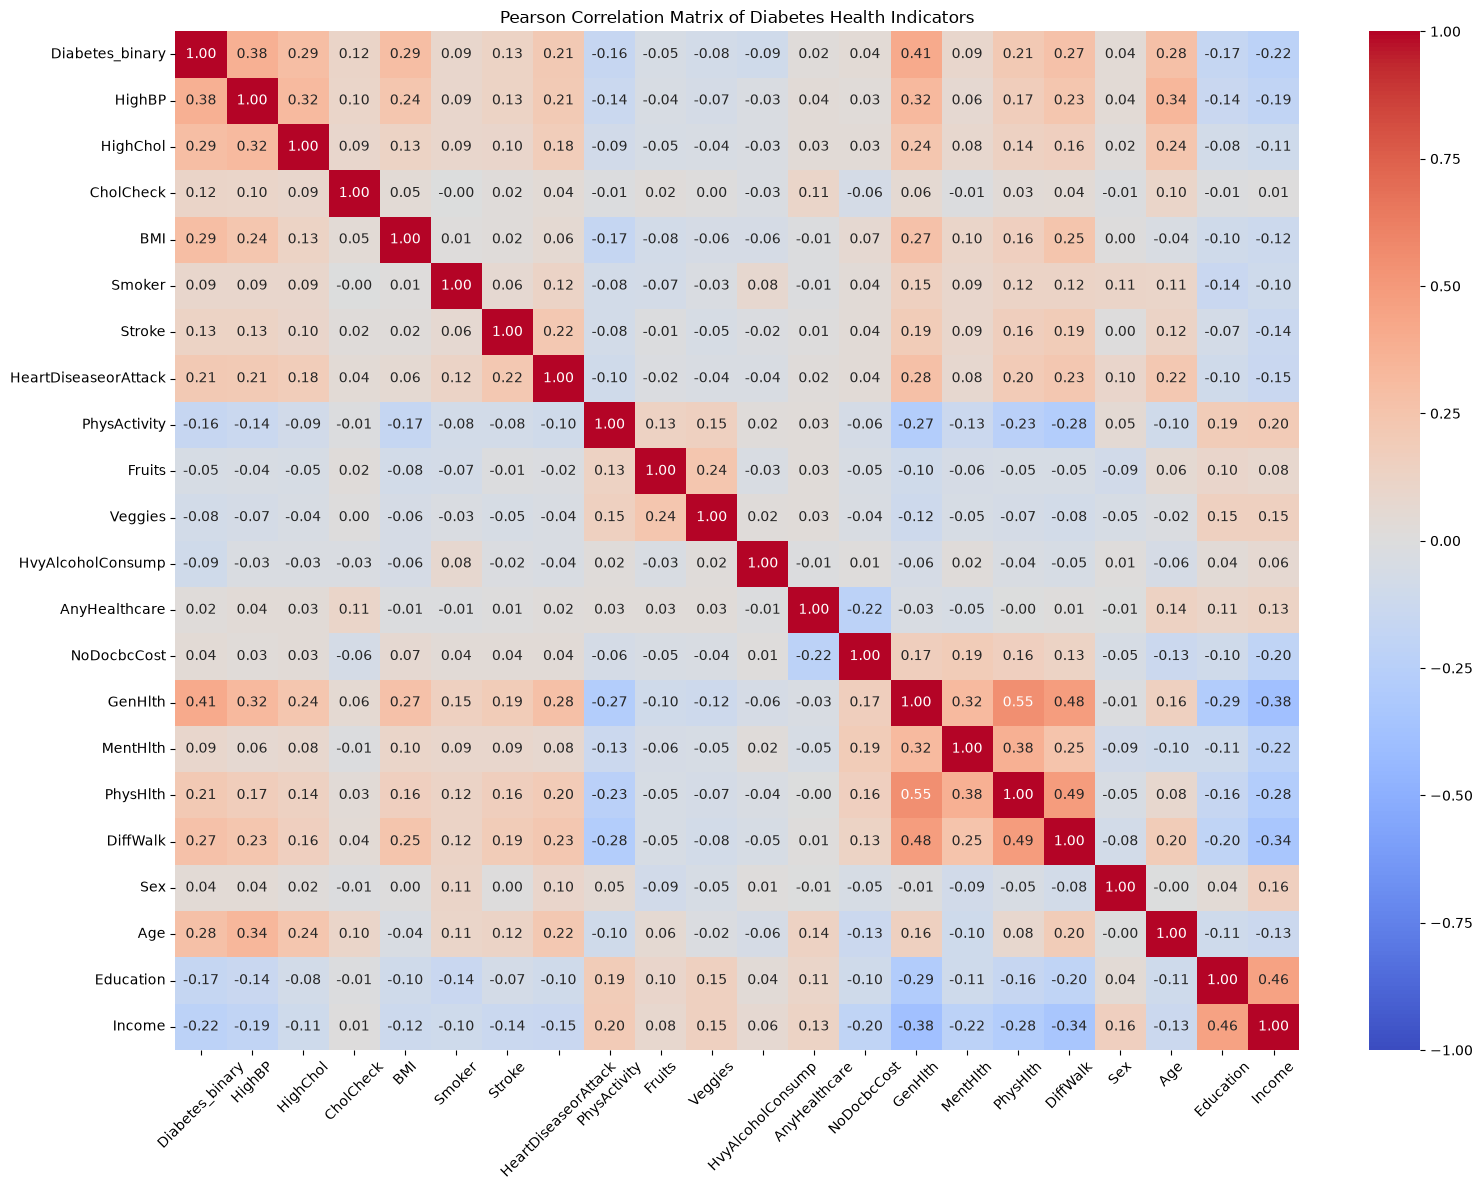

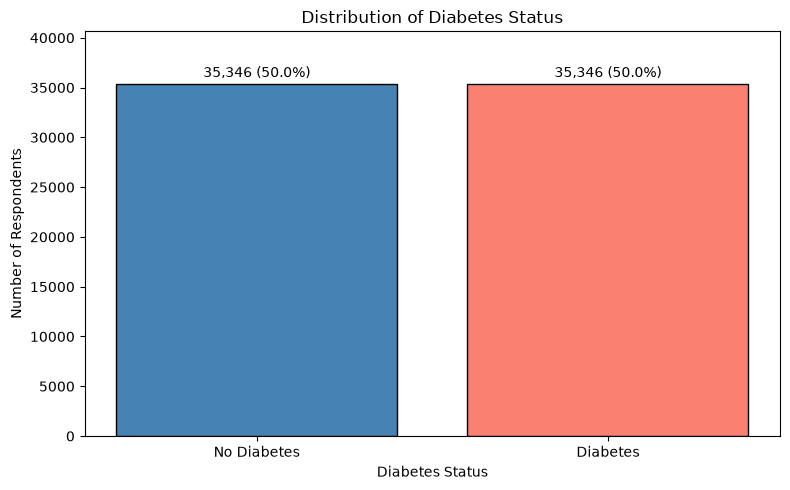

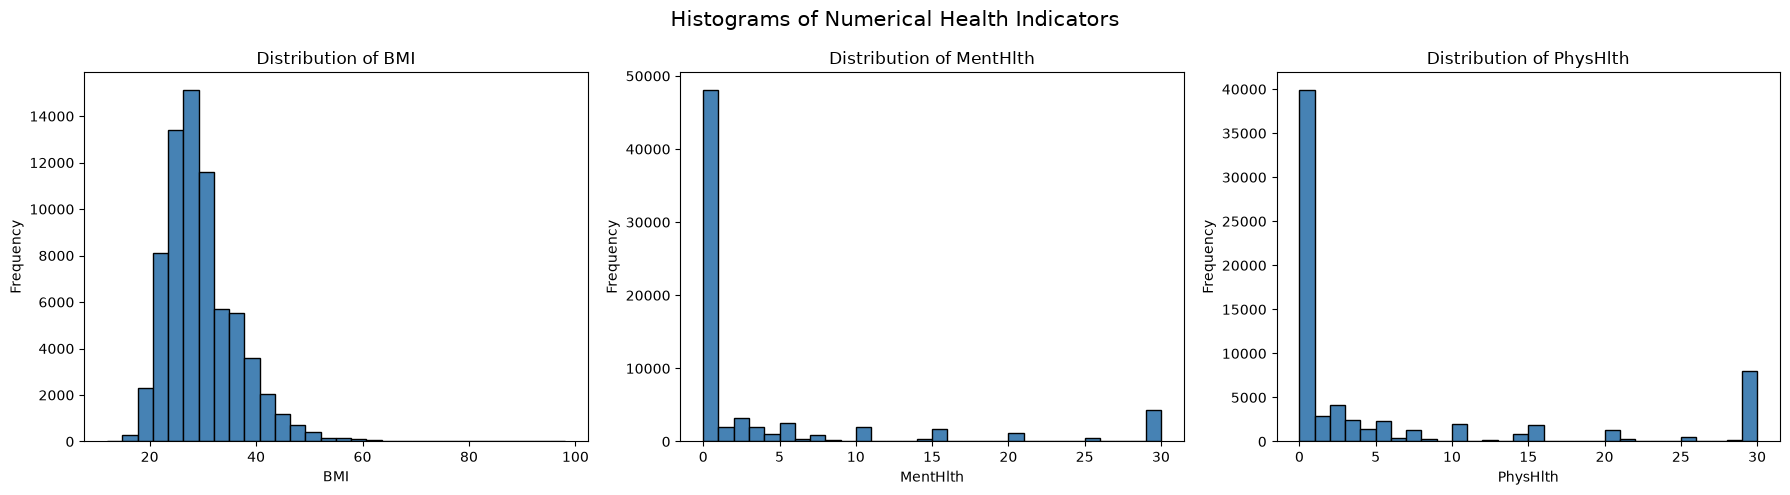

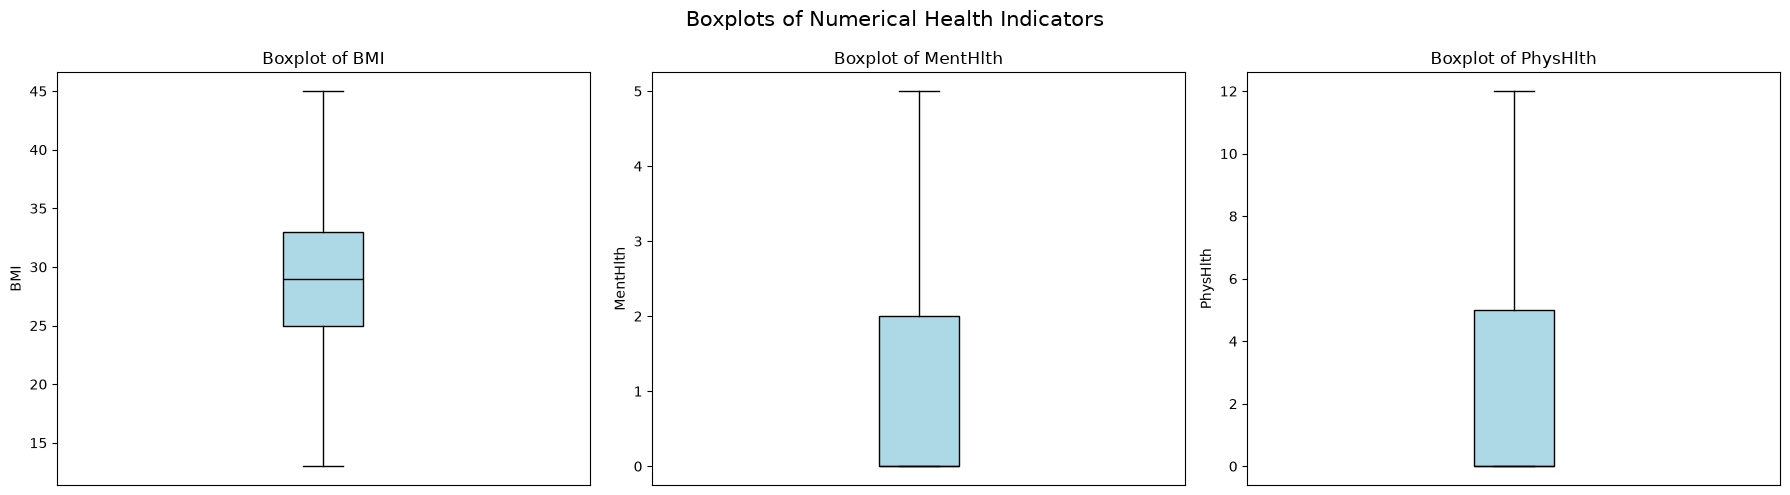

4-executor warm-up runtime: 29.757 seconds


In [68]:
# Warm-up run for 4 executors

warmup_4 = run_statistical_benchmark(num_executors=4)

print(
    f"4-executor warm-up runtime: "
    f"{warmup_4['Runtime_seconds']:.3f} seconds"
)


DESCRIPTIVE STATISTICS


,summary,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,count,70692,70692,70692,70692,70692,70692,70692,70692,70692,...,70692,70692,70692,70692,70692,70692,70692,70692,70692,70692
1,mean,0.5,0.5634583828438862,0.5257030498500538,0.975258869461891,29.856985231709388,0.4752730153341255,0.0621711084705483,0.1478102189781022,0.7030357041815198,...,0.9549595428054094,0.09391444576472585,2.837081989475471,3.7520370056017653,5.810417020313473,0.25273015334125504,0.4569965484071748,8.584054772817291,4.920952865953715,5.698310982855203
2,stddev,0.500003536505579,0.49596019315986284,0.4993424480263366,0.1553362428040657,7.113953851576819,0.4993917341107826,0.2414677753677074,0.354914271361942,0.456923906350966,...,0.2073943655419098,0.2917117179591919,1.1135645170395423,8.155626553608052,10.06226053116388,0.4345805961233848,0.4981507939458711,2.852153109951339,1.029080800484773,2.175195975918353
3,min,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,max,1.0,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0



DIABETES FREQUENCY DISTRIBUTION


,Diabetes_binary,Frequency,Percentage
0,0.0,35346,50.0
1,1.0,35346,50.0



BOXPLOT STATISTICS


,med,q1,q3,whislo,whishi,fliers
BMI,29.0,25.0,33.0,13.0,45.0,[]
MentHlth,0.0,0.0,2.0,0.0,5.0,[]
PhysHlth,0.0,0.0,5.0,0.0,12.0,[]



PEARSON CORRELATION WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


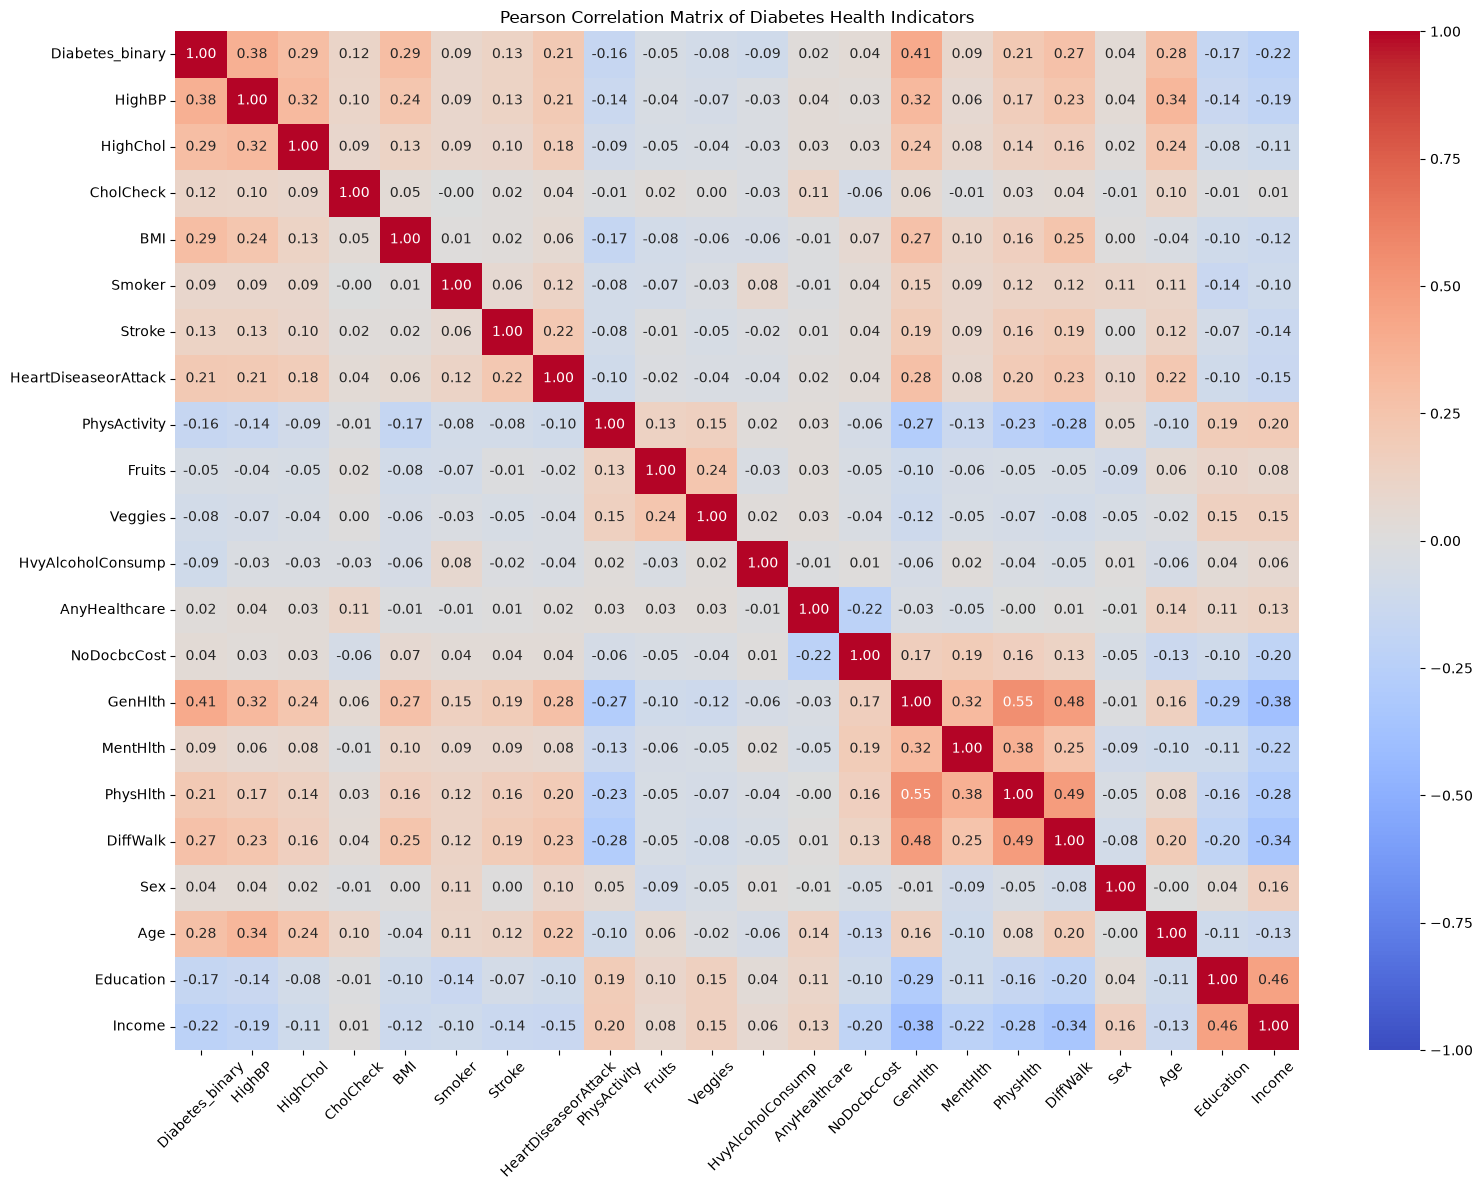

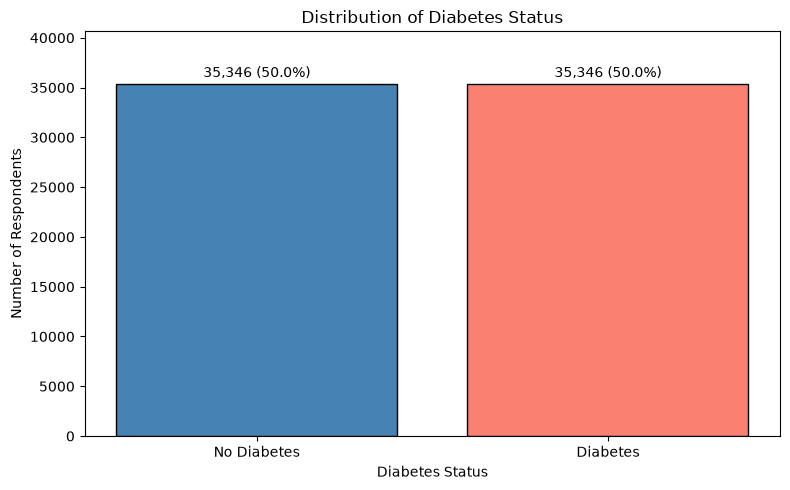

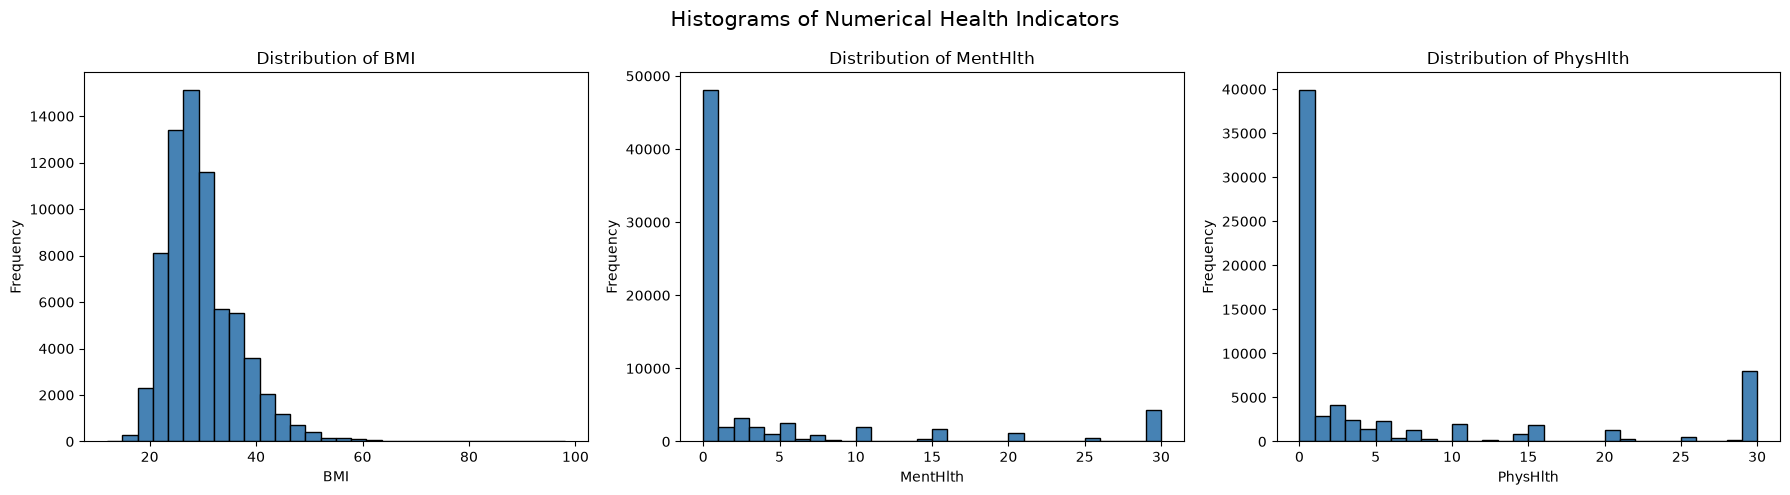

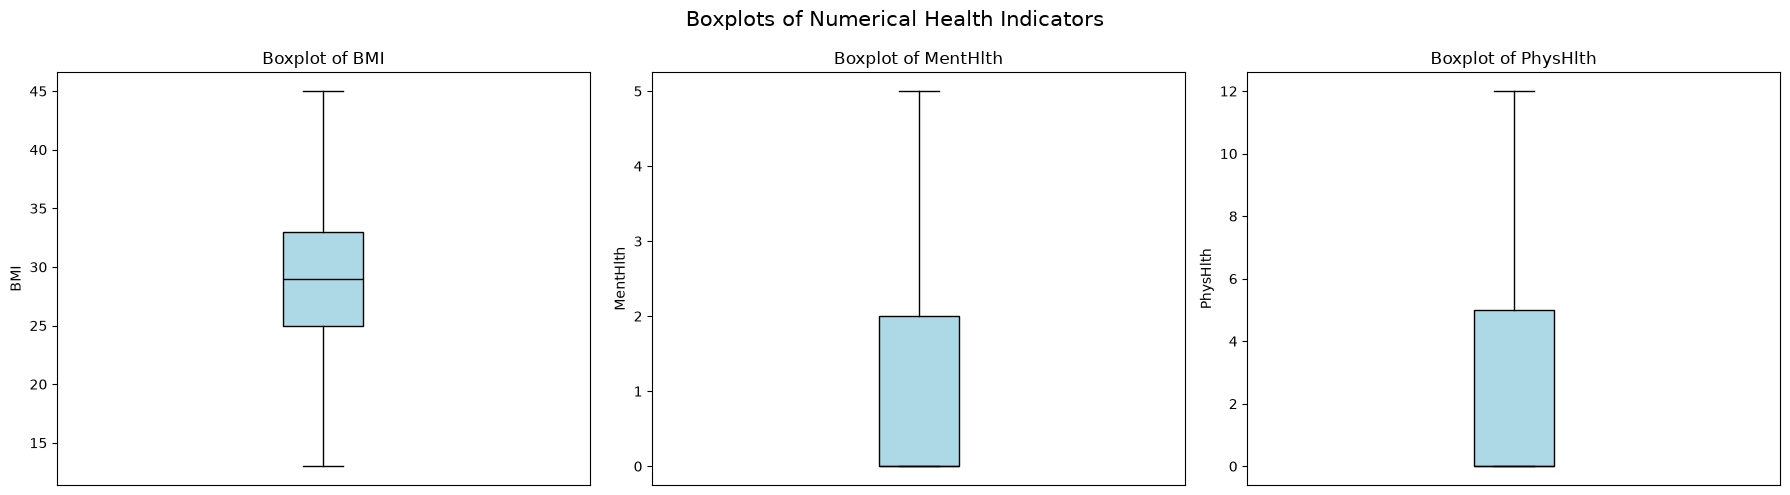

Run 1: 15.909 seconds

DESCRIPTIVE STATISTICS


,summary,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,count,70692,70692,70692,70692,70692,70692,70692,70692,70692,...,70692,70692,70692,70692,70692,70692,70692,70692,70692,70692
1,mean,0.5,0.5634583828438862,0.5257030498500538,0.975258869461891,29.856985231709388,0.4752730153341255,0.0621711084705483,0.1478102189781022,0.7030357041815198,...,0.9549595428054094,0.09391444576472585,2.837081989475471,3.7520370056017653,5.810417020313473,0.25273015334125504,0.4569965484071748,8.584054772817291,4.920952865953715,5.698310982855203
2,stddev,0.500003536505579,0.49596019315986284,0.4993424480263366,0.1553362428040657,7.113953851576819,0.4993917341107826,0.2414677753677074,0.354914271361942,0.456923906350966,...,0.2073943655419098,0.2917117179591919,1.1135645170395423,8.155626553608052,10.06226053116388,0.4345805961233848,0.4981507939458711,2.852153109951339,1.029080800484773,2.175195975918353
3,min,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,max,1.0,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0



DIABETES FREQUENCY DISTRIBUTION


,Diabetes_binary,Frequency,Percentage
0,0.0,35346,50.0
1,1.0,35346,50.0



BOXPLOT STATISTICS


,med,q1,q3,whislo,whishi,fliers
BMI,29.0,25.0,33.0,13.0,45.0,[]
MentHlth,0.0,0.0,2.0,0.0,5.0,[]
PhysHlth,0.0,0.0,5.0,0.0,12.0,[]



PEARSON CORRELATION WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


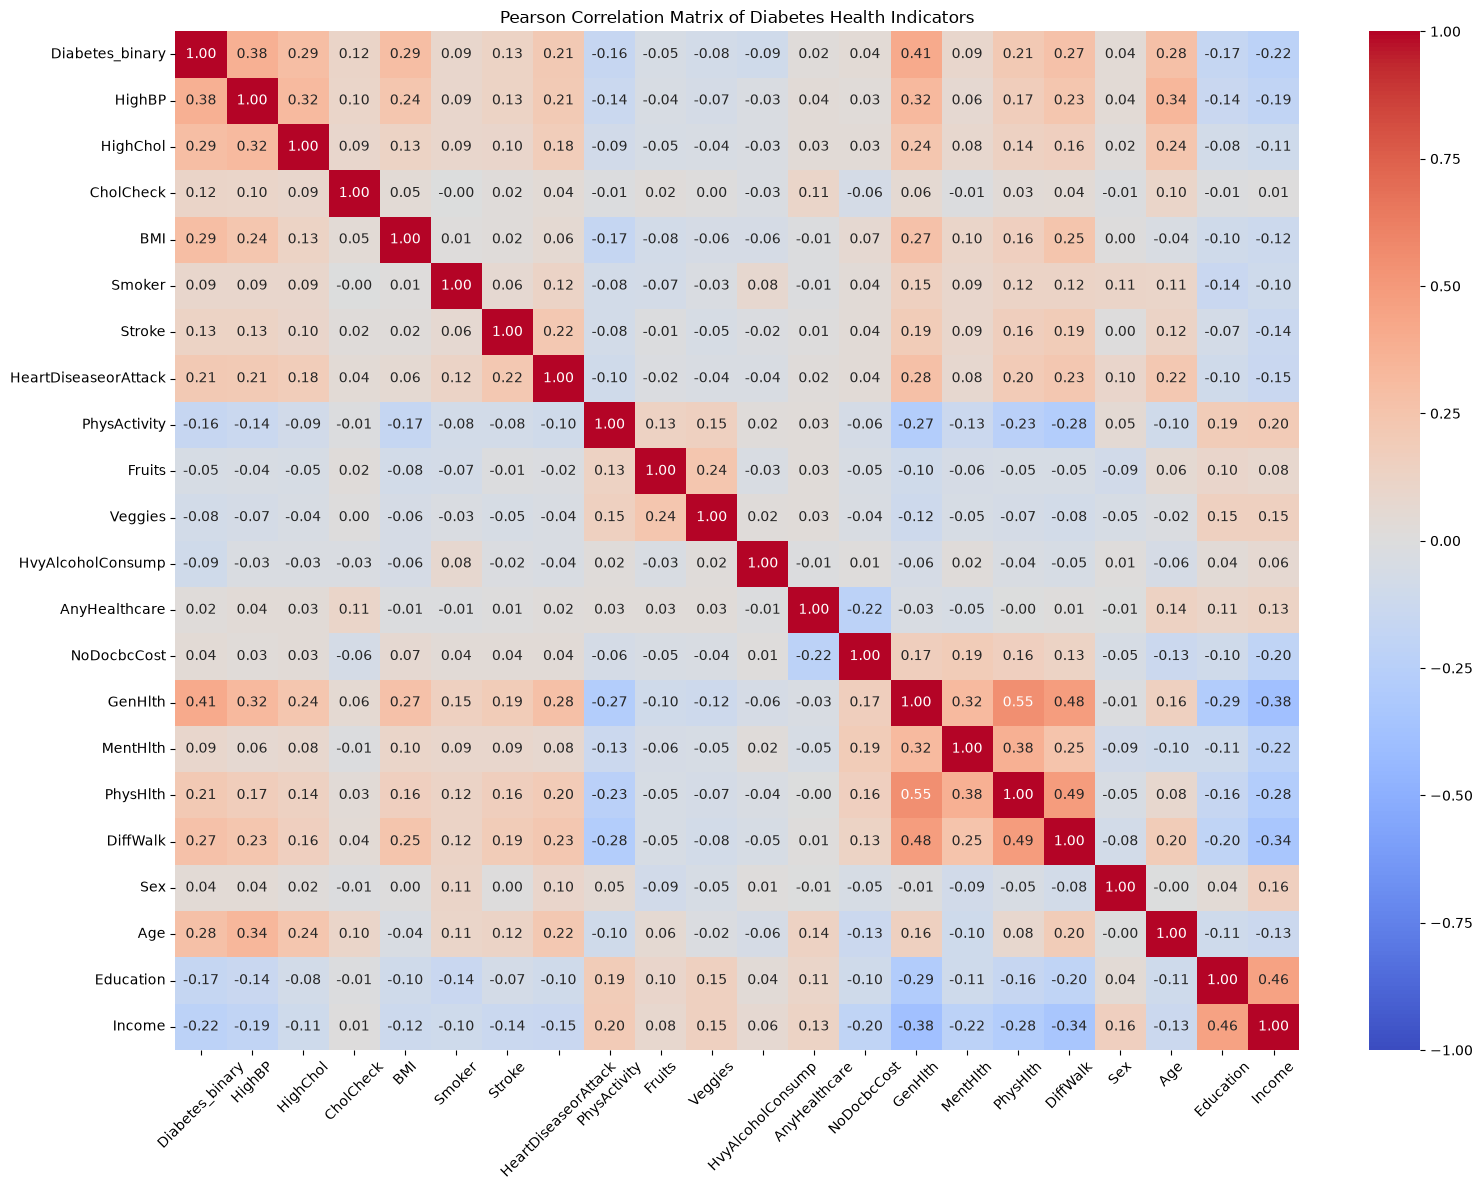

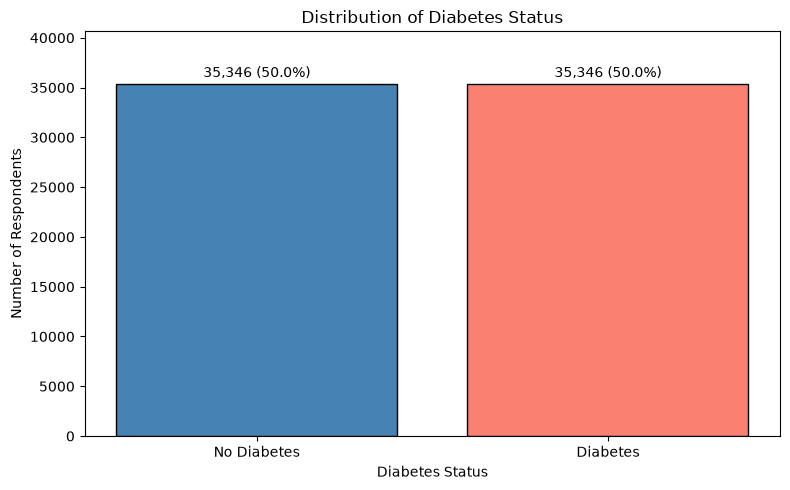

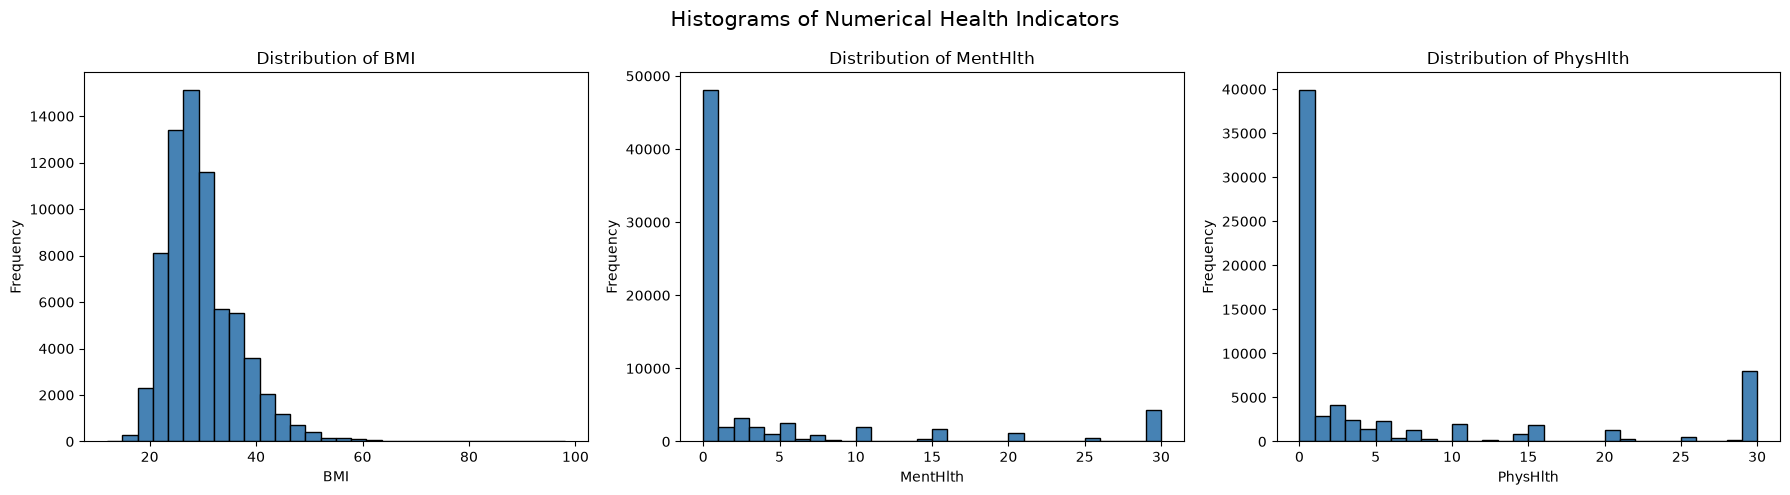

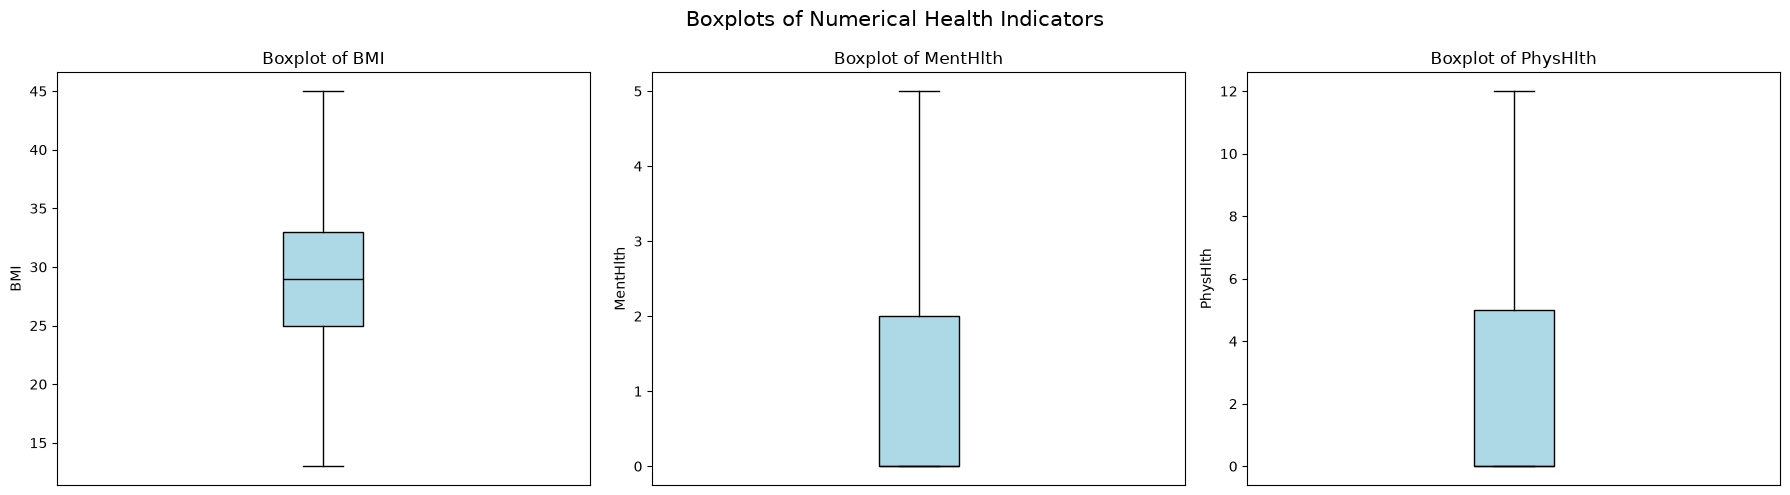

Run 2: 9.946 seconds

DESCRIPTIVE STATISTICS


,summary,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,count,70692,70692,70692,70692,70692,70692,70692,70692,70692,...,70692,70692,70692,70692,70692,70692,70692,70692,70692,70692
1,mean,0.5,0.5634583828438862,0.5257030498500538,0.975258869461891,29.856985231709388,0.4752730153341255,0.0621711084705483,0.1478102189781022,0.7030357041815198,...,0.9549595428054094,0.09391444576472585,2.837081989475471,3.7520370056017653,5.810417020313473,0.25273015334125504,0.4569965484071748,8.584054772817291,4.920952865953715,5.698310982855203
2,stddev,0.500003536505579,0.49596019315986284,0.4993424480263366,0.1553362428040657,7.113953851576819,0.4993917341107826,0.2414677753677074,0.354914271361942,0.456923906350966,...,0.2073943655419098,0.2917117179591919,1.1135645170395423,8.155626553608052,10.06226053116388,0.4345805961233848,0.4981507939458711,2.852153109951339,1.029080800484773,2.175195975918353
3,min,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,max,1.0,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0



DIABETES FREQUENCY DISTRIBUTION


,Diabetes_binary,Frequency,Percentage
0,0.0,35346,50.0
1,1.0,35346,50.0



BOXPLOT STATISTICS


,med,q1,q3,whislo,whishi,fliers
BMI,29.0,25.0,33.0,13.0,45.0,[]
MentHlth,0.0,0.0,2.0,0.0,5.0,[]
PhysHlth,0.0,0.0,5.0,0.0,12.0,[]



PEARSON CORRELATION WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


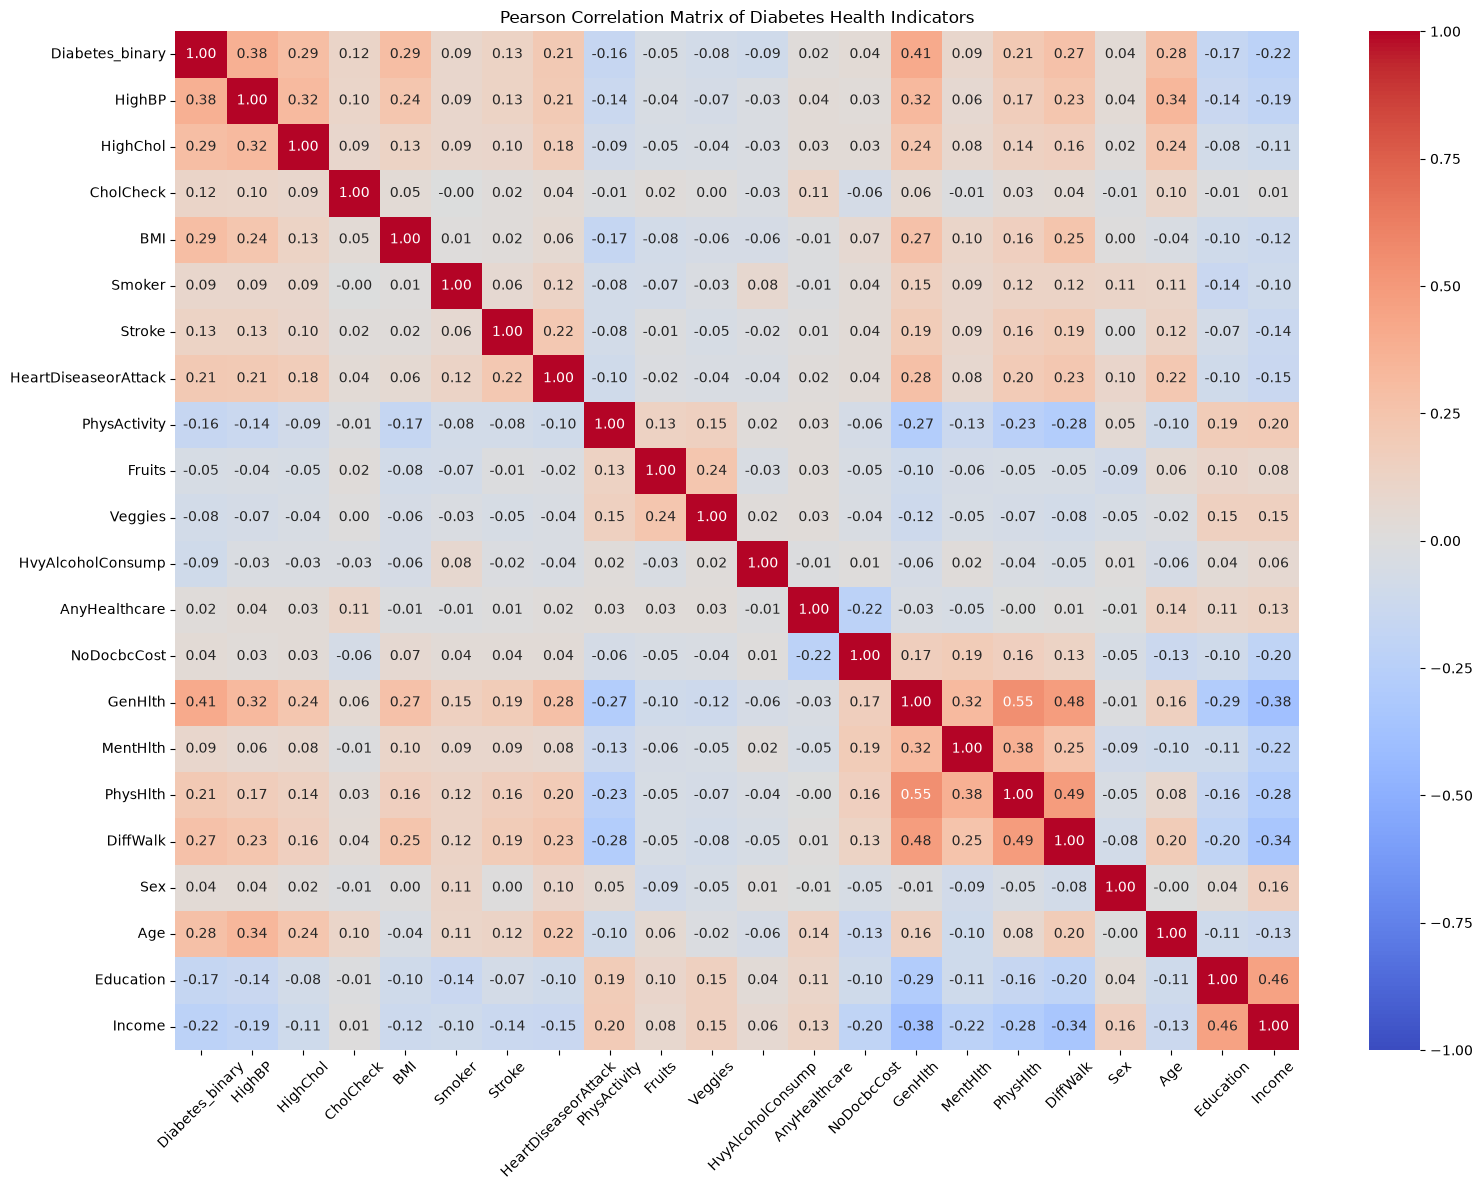

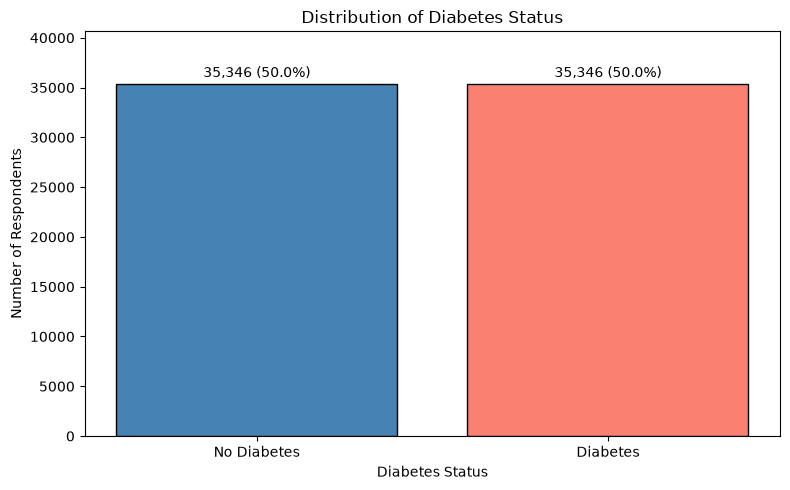

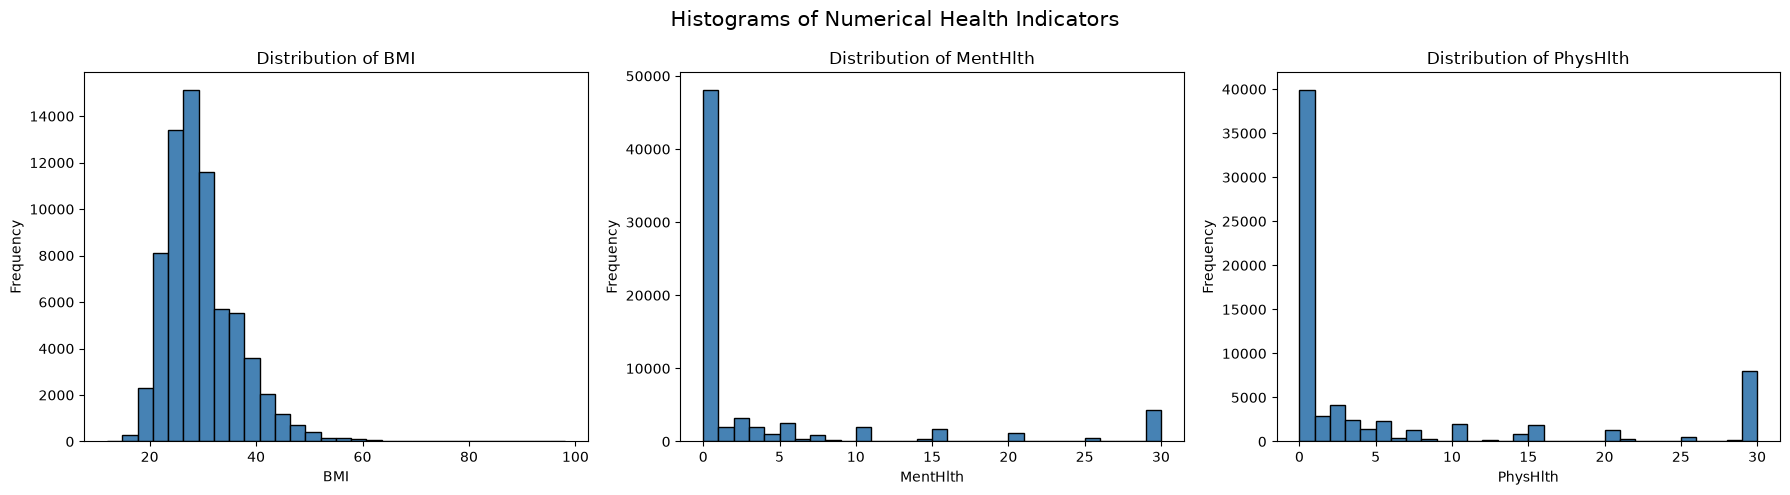

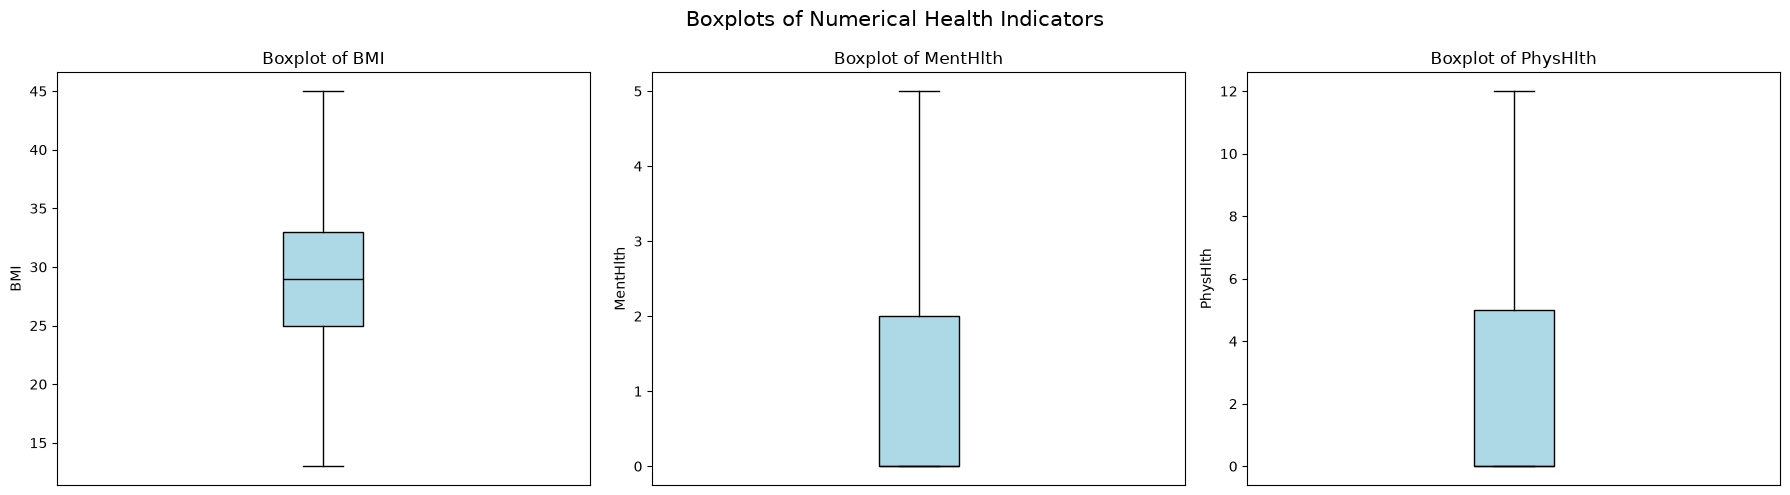

Run 3: 8.445 seconds


In [69]:
results_4_executor = []

for run in range(1, 4):

    result = run_statistical_benchmark(num_executors=4)

    result["Run"] = run
    results_4_executor.append(result)

    print(
        f"Run {run}: "
        f"{result['Runtime_seconds']:.3f} seconds"
    )

In [70]:
results_4_df = pd.DataFrame(results_4_executor)

results_4_df = results_4_df[
    [
        "Run",
        "Executors",
        "Runtime_seconds",
        "Partitions",
        "CPU_count",
        "Available_RAM_GB"
    ]
]

results_4_df

,Run,Executors,Runtime_seconds,Partitions,CPU_count,Available_RAM_GB
0,1,4,15.909108,2,16,0.258083
1,2,4,9.946076,2,16,1.320709
2,3,4,8.444752,2,16,1.721691


In [71]:
mean_runtime_4 = results_4_df["Runtime_seconds"].mean()
std_runtime_4 = results_4_df["Runtime_seconds"].std()

print(f"Mean runtime: {mean_runtime_4:.3f} seconds")
print(f"Standard deviation: {std_runtime_4:.3f} seconds")

Mean runtime: 11.433 seconds
Standard deviation: 3.948 seconds


In [72]:
full_comparison_df = pd.DataFrame({
    "Executors": [1, 2, 4],

    "Mean_Runtime_s": [
        results_1_df["Runtime_seconds"].mean(),
        results_2_df["Runtime_seconds"].mean(),
        results_4_df["Runtime_seconds"].mean()
    ],

    "Std_Runtime_s": [
        results_1_df["Runtime_seconds"].std(),
        results_2_df["Runtime_seconds"].std(),
        results_4_df["Runtime_seconds"].std()
    ]
})

baseline_runtime = full_comparison_df.loc[
    full_comparison_df["Executors"] == 1,
    "Mean_Runtime_s"
].iloc[0]

full_comparison_df["Speedup"] = (
    baseline_runtime / full_comparison_df["Mean_Runtime_s"]
)

full_comparison_df

,Executors,Mean_Runtime_s,Std_Runtime_s,Speedup
0,1,7.926497,0.207409,1.000000
1,2,8.696861,0.713499,0.911420
2,4,11.433312,3.948171,0.693281


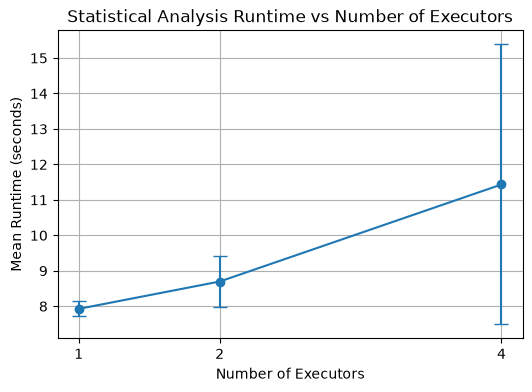

In [73]:
plt.figure(figsize=(6,4))

plt.errorbar(
    full_comparison_df["Executors"],
    full_comparison_df["Mean_Runtime_s"],
    yerr=full_comparison_df["Std_Runtime_s"],
    marker="o",
    capsize=5
)

plt.xlabel("Number of Executors")
plt.ylabel("Mean Runtime (seconds)")
plt.title("Statistical Analysis Runtime vs Number of Executors")
plt.xticks([1, 2, 4])
plt.grid(True)
plt.show()

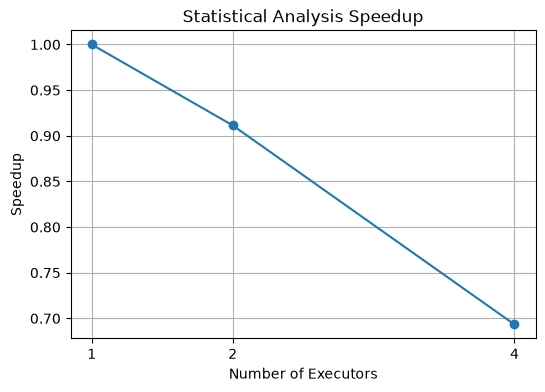

In [74]:
plt.figure(figsize=(6,4))

plt.plot(
    full_comparison_df["Executors"],
    full_comparison_df["Speedup"],
    marker="o"
)

plt.xlabel("Number of Executors")
plt.ylabel("Speedup")
plt.title("Statistical Analysis Speedup")
plt.xticks([1, 2, 4])
plt.grid(True)
plt.show()